# 1. Setup

In [ ]:
# Setup: import libraries, fix the random seed, mount Google Drive and create the output folders
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import shap
import sklearn
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error, confusion_matrix,
                             precision_score, recall_score, f1_score, silhouette_score)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import xgboost as xgb
from xgboost import XGBRegressor
import lightgbm as lgb
from lightgbm import LGBMRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Colab Notebooks/Environmental-ML-Project")
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

for lib in (np, pd, sklearn, xgb, lgb, mpl):
    print(f"{lib.__name__:12s} {lib.__version__}")

Mounted at /content/drive
numpy        2.4.6
pandas       2.2.3
sklearn      1.6.1
xgboost      3.4.1
lightgbm     4.6.0
matplotlib   3.10.0


In [ ]:
# Chart style (colours, fonts) and two helper functions: save_fig() and regression_metrics()
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW = PALETTE[:4]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"          # text colours
GRID, AXIS, SURFACE, CRITICAL = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#d03b3b"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#1c5cab", "#f0efec", "#c9302c"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "font.size": 11,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "legend.fontsize": 10, "figure.dpi": 96,
})

def save_fig(name):
    """Save the current figure into figures/ at slide quality."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

def regression_metrics(y_true, y_pred):
    """R², MAE and RMSE — the regression metrics used in the course labs."""
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

# 2. Load and inspect the data

In [ ]:
# Load the raw hourly data (PRSA_data.csv) and show the first rows
RAW_FILE = DATA_DIR / "PRSA_data.csv"
raw = pd.read_csv(RAW_FILE)
print("Shape:", raw.shape)
raw.head()

Shape: (43824, 13)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [ ]:
# Column names, data types and number of non-missing values in the raw data
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  object 
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), object(1)
memory usage: 4.3+ MB


In [ ]:
# Summary statistics of every raw column
raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
No,43824.0,21912.50,12651.04,1.00,10956.75,21912.50,32868.25,43824.0
year,43824.0,2012.00,1.41,2010.00,2011.00,2012.00,2013.00,2014.0
month,43824.0,6.52,3.45,1.00,4.00,7.00,10.00,12.0
day,43824.0,15.73,8.80,1.00,8.00,16.00,23.00,31.0
hour,43824.0,11.50,6.92,0.00,5.75,11.50,17.25,23.0
pm2.5,41757.0,98.61,92.05,0.00,29.00,72.00,137.00,994.0
DEWP,43824.0,1.82,14.43,-40.00,-10.00,2.00,15.00,28.0
TEMP,43824.0,12.45,12.20,-19.00,2.00,14.00,23.00,42.0
PRES,43824.0,1016.45,10.27,991.00,1008.00,1016.00,1025.00,1046.0
Iws,43824.0,23.89,50.01,0.45,1.79,5.37,21.91,585.6


# 3. Data cleaning and preprocessing (hourly data)

## 3.1 Time index, duplicates and missing values

In [ ]:
# Build the hourly time index and check time steps, duplicates and missing values (PM2.5 gaps per year)
hourly = raw.copy()
hourly["datetime"] = pd.to_datetime(hourly[["year", "month", "day", "hour"]])
hourly = hourly.set_index("datetime").drop(columns=["No"]).rename(columns={"pm2.5": "PM25"})

steps = hourly.index.to_series().diff().dropna().value_counts()
print("Time step between consecutive records:", {str(k): int(v) for k, v in steps.items()})
print("Duplicated rows:", hourly.duplicated().sum(), "| duplicated timestamps:", hourly.index.duplicated().sum())

missing = hourly.isnull().sum()
print("\nColumns with missing values:\n", missing[missing > 0].to_string())
print(f"Share of hours without a PM2.5 value: {hourly['PM25'].isna().mean():.1%}")

hourly["PM25"].isna().groupby(hourly.index.year).sum().rename("missing PM2.5 hours").to_frame().T

Time step between consecutive records: {'0 days 01:00:00': 43823}
Duplicated rows: 0 | duplicated timestamps: 0

Columns with missing values:
 PM25    2067
Share of hours without a PM2.5 value: 4.7%


datetime,2010,2011,2012,2013,2014
missing PM2.5 hours,669,728,489,82,99


## 3.2 Recovering hourly wind speed and relative humidity

In [ ]:
# Recover hourly wind speed from the cumulated Iws column and compute relative humidity from TEMP and DEWP
same_direction = hourly["cbwd"].eq(hourly["cbwd"].shift(1))
hourly["WS"] = np.where(same_direction, hourly["Iws"] - hourly["Iws"].shift(1), hourly["Iws"])

def saturation_vapour_pressure(t_celsius):
    return 6.1094 * np.exp(17.625 * t_celsius / (t_celsius + 243.04))

hourly["RH"] = (100 * saturation_vapour_pressure(hourly["DEWP"])
                / saturation_vapour_pressure(hourly["TEMP"])).clip(upper=100)

print("Negative wind speeds after reconstruction:", int((hourly["WS"] < 0).sum()))
hourly[["WS", "RH"]].describe().round(2).T

Negative wind speeds after reconstruction: 0


,count,mean,std,min,25%,50%,75%,max
WS,43824.0,2.94,2.36,0.45,0.89,1.79,4.02,20.12
RH,43824.0,54.82,25.93,2.69,31.59,55.32,78.06,100.00


## 3.3 Outliers: errors or real pollution events?

In [ ]:
# Outlier check: count hours above the 1.5×IQR fence
q1, q3 = hourly["PM25"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
n_out = (hourly["PM25"] > upper_fence).sum()
print(f"1.5×IQR upper fence = {upper_fence:.0f} µg/m³ -> {n_out} hours ({n_out / hourly['PM25'].notna().sum():.1%}) lie above it")

extreme = hourly.nlargest(15, "PM25")[["PM25", "cbwd", "WS", "RH", "TEMP"]].round(1)
extreme

1.5×IQR upper fence = 299 µg/m³ -> 1773 hours (4.2%) lie above it


,PM25,cbwd,WS,RH,TEMP
datetime,,,,,
2012-01-23 01:00:00,994.0,NW,1.8,36.2,-12.0
2010-02-14 01:00:00,980.0,cv,0.9,57.4,-7.0
2012-01-23 02:00:00,972.0,NW,3.1,36.2,-12.0
2013-01-12 20:00:00,886.0,cv,0.5,92.6,-7.0
2013-01-12 22:00:00,858.0,cv,0.9,92.4,-9.0
2013-01-12 21:00:00,852.0,NE,0.9,92.5,-8.0
2013-01-12 16:00:00,845.0,SE,1.8,68.6,-2.0
2013-01-12 19:00:00,824.0,cv,0.9,92.6,-7.0
2013-01-12 17:00:00,810.0,SE,0.9,79.6,-4.0


# 4. Feature engineering: from hourly records to a daily forecasting table

In [ ]:
# Aggregate hourly data to daily values + evening PM2.5
VALID_HOURS = 20                       # GB 3095-2012 guideline
day = hourly.index.normalize()
g = hourly.groupby(day)

evening = hourly[hourly.index.hour >= 18]                # 18:00-23:00, the latest data before the forecast
evening_stats = evening.groupby(evening.index.normalize())["PM25"].agg(["mean", "count"])

daily = pd.DataFrame({
    "PM25": g["PM25"].mean(),
    "PM25_hours": g["PM25"].count(),
    "PM25_evening": evening_stats["mean"].where(evening_stats["count"] >= 3),
    "TEMP": g["TEMP"].mean(),
    "TEMP_range": g["TEMP"].max() - g["TEMP"].min(),
    "DEWP": g["DEWP"].mean(),
    "RH": g["RH"].mean(),
    "PRES": g["PRES"].mean(),
    "WS": g["WS"].mean(),
    "rain_hours": g["Ir"].apply(lambda s: int((s > 0).sum())),
    "snow_hours": g["Is"].apply(lambda s: int((s > 0).sum())),
    "frac_NW": g["cbwd"].apply(lambda s: (s == "NW").mean()),
    "frac_NE": g["cbwd"].apply(lambda s: (s == "NE").mean()),
    "frac_SE": g["cbwd"].apply(lambda s: (s == "SE").mean()),
    "frac_cv": g["cbwd"].apply(lambda s: (s == "cv").mean()),
    "main_wind": g["cbwd"].agg(lambda s: s.value_counts().idxmax()),
})
daily.index.name = "date"
daily.loc[daily["PM25_hours"] < VALID_HOURS, "PM25"] = np.nan
print(f"{len(daily)} days, {daily['PM25'].notna().sum()} with a valid daily PM2.5 mean "
      f"({daily['PM25'].isna().sum()} days rejected for having < {VALID_HOURS} hourly values)")

1826 days, 1711 with a valid daily PM2.5 mean (115 days rejected for having < 20 hourly values)


In [ ]:
# Create the 21 model features (change, persistence, calendar), define the feature groups

# Change features (day t vs day t-1): passing fronts and changing air masses
daily["dPRES"] = daily["PRES"].diff()   # pressure today − pressure yesterday
daily["dDEWP"] = daily["DEWP"].diff()   # dew point today − dew point yesterday

# Persistence: pollution already in the air before the forecast day
daily["PM_lag1"] = daily["PM25"].shift(1)              # yesterday's daily mean
daily["PM_eve_lag1"] = daily["PM25_evening"].shift(1)  # yesterday 18:00-23:00 mean
daily["PM_lag2"] = daily["PM25"].shift(2)              # two days ago

# Calendar features
doy = daily.index.dayofyear
daily["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)    # cyclic encoding of the season
daily["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
daily["weekend"] = (daily.index.dayofweek >= 5).astype(int)
month_day = daily.index.month * 100 + daily.index.day
daily["heating_season"] = ((month_day >= 1115) | (month_day <= 315)).astype(int)  # 15 Nov - 15 Mar
LUNAR_NEW_YEAR = pd.to_datetime(["2010-02-14", "2011-02-03", "2012-01-23", "2013-02-10", "2014-01-31"])
festival = LUNAR_NEW_YEAR.union(LUNAR_NEW_YEAR - pd.Timedelta(days=1))           # eve + New Year's day
daily["spring_festival"] = daily.index.isin(festival).astype(int)

WEATHER = ["TEMP", "TEMP_range", "DEWP", "RH", "PRES", "WS", "rain_hours", "snow_hours",
           "frac_NW", "frac_SE", "frac_cv", "dPRES", "dDEWP"]
PERSISTENCE = ["PM_lag1", "PM_eve_lag1", "PM_lag2"]
CALENDAR = ["doy_sin", "doy_cos", "weekend", "heating_season", "spring_festival"]
FEATURES = WEATHER + PERSISTENCE + CALENDAR
TARGET = "PM25"
print(f"{len(FEATURES)} features: {len(WEATHER)} weather, {len(PERSISTENCE)} persistence, {len(CALENDAR)} calendar")

daily[FEATURES + [TARGET, "main_wind"]].to_csv(DATA_DIR / "beijing_pm25_daily_features.csv")
daily[FEATURES + [TARGET]].describe().round(2).T

21 features: 13 weather, 3 persistence, 5 calendar


,count,mean,std,min,25%,50%,75%,max
TEMP,1826.0,12.45,11.56,-14.46,1.54,13.90,23.17,32.88
TEMP_range,1826.0,11.03,4.29,0.00,8.00,11.00,14.00,24.00
DEWP,1826.0,1.82,14.17,-33.33,-10.08,2.02,15.07,26.21
RH,1826.0,54.82,20.24,7.28,38.16,55.29,71.28,98.02
PRES,1826.0,1016.45,10.07,994.04,1007.94,1016.23,1024.53,1043.46
WS,1826.0,2.94,1.57,0.89,1.90,2.46,3.45,9.95
rain_hours,1826.0,0.99,2.74,0.00,0.00,0.00,0.00,24.00
snow_hours,1826.0,0.20,1.41,0.00,0.00,0.00,0.00,22.00
frac_NW,1826.0,0.32,0.29,0.00,0.08,0.25,0.50,1.00
frac_SE,1826.0,0.35,0.26,0.00,0.12,0.33,0.54,1.00


# 5. Exploratory Data Analysis

## 5.1 Visualization

Days with valid data: 1711
Mean daily PM2.5: 98.7 µg/m³ | median 78.5 | max 552.5 (12 Jan 2013)
Days above China's 24-h standard (75 µg/m³): 52.4%
Days above the WHO 2021 guideline (15 µg/m³): 96.1%


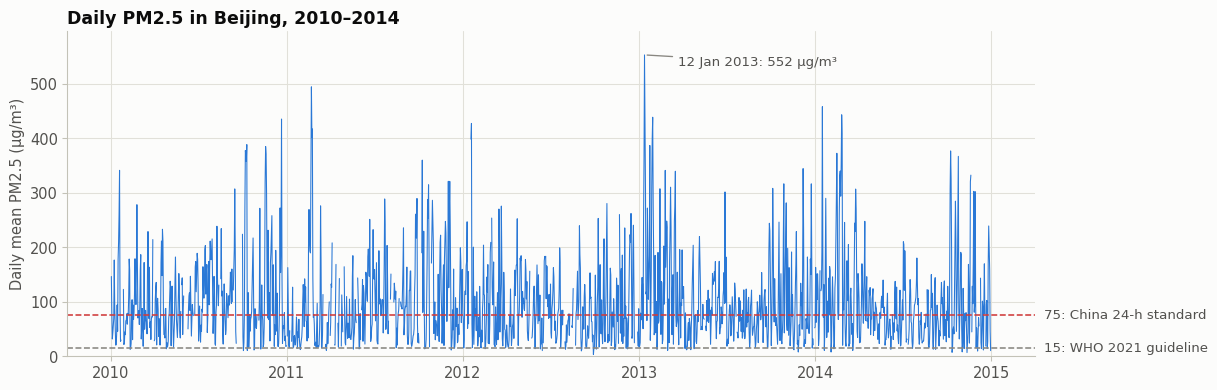

,mean,median,days,share_above_75
date,,,,
2010,104.19,83.77,330,0.58
2011,99.10,77.12,324,0.51
2012,89.85,75.19,340,0.50
2013,101.98,77.10,360,0.51
2014,98.17,78.33,357,0.52


In [ ]:
# EDA 1: daily PM2.5 time series 2010–2014 with the China and WHO limits (Figure 1) + yearly summary
valid = daily["PM25"].dropna()
print(f"Days with valid data: {len(valid)}")
print(f"Mean daily PM2.5: {valid.mean():.1f} µg/m³ | median {valid.median():.1f} | max {valid.max():.1f} ({valid.idxmax():%d %b %Y})")
print(f"Days above China's 24-h standard (75 µg/m³): {(valid > 75).mean():.1%}")
print(f"Days above the WHO 2021 guideline (15 µg/m³): {(valid > 15).mean():.1%}")

fig, ax = plt.subplots(figsize=(13, 4.4))
ax.plot(daily.index, daily["PM25"].values, color=BLUE, linewidth=0.8)   # gaps = days without valid data
ax.axhline(75, color=CRITICAL, linewidth=1.2, linestyle="--")
ax.axhline(15, color=MUTED, linewidth=1.2, linestyle="--")
ax.text(1.01, 75, "75: China 24-h standard", transform=ax.get_yaxis_transform(), color=INK2, fontsize=10, va="center")
ax.text(1.01, 15, "15: WHO 2021 guideline", transform=ax.get_yaxis_transform(), color=INK2, fontsize=10, va="center")
peak = valid.idxmax()
ax.annotate(f"{peak:%d %b %Y}: {valid.max():.0f} µg/m³", xy=(peak, valid.max()), xytext=(25, -5),
            textcoords="offset points", color=INK2, fontsize=10, va="center",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("Daily PM2.5 in Beijing, 2010–2014")
ax.set_ylim(0, valid.max() * 1.08)
save_fig("01_daily_pm25_timeseries")
plt.show()

yearly = valid.groupby(valid.index.year).agg(mean="mean", median="median", days="count",
                                             share_above_75=lambda s: (s > 75).mean())
yearly.round(2)

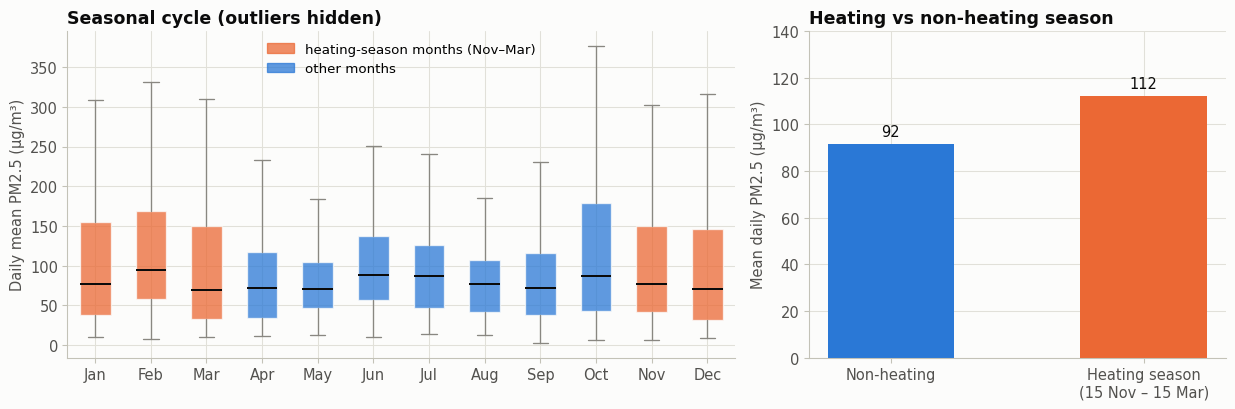

Heating season mean is 22% higher than the non-heating season mean


In [ ]:
# EDA 2: seasonal cycle by month and heating vs non-heating season (Figure 2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
months = [valid[valid.index.month == m].values for m in range(1, 13)]
heating_months = {1, 2, 3, 11, 12}
bp = ax.boxplot(months, patch_artist=True, widths=0.55, showfliers=False,
                medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=MUTED),
                capprops=dict(color=MUTED))
for m, box in enumerate(bp["boxes"], start=1):
    box.set_facecolor(ORANGE if m in heating_months else BLUE)
    box.set_alpha(0.75)
    box.set_edgecolor(SURFACE)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("Seasonal cycle (outliers hidden)")
ax.legend(handles=[mpl.patches.Patch(color=ORANGE, alpha=0.75, label="heating-season months (Nov–Mar)"),
                   mpl.patches.Patch(color=BLUE, alpha=0.75, label="other months")], loc="upper center")

ax = axes[1]
heat = daily.loc[valid.index, "heating_season"]
means = [valid[heat == 0].mean(), valid[heat == 1].mean()]
bars = ax.bar(["Non-heating", "Heating season\n(15 Nov – 15 Mar)"], means, color=[BLUE, ORANGE], width=0.5)
for b, v in zip(bars, means):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v:.0f}", ha="center", va="bottom", color=INK, fontsize=11)
ax.set_ylabel("Mean daily PM2.5 (µg/m³)")
ax.set_title("Heating vs non-heating season")
ax.set_ylim(0, max(means) * 1.25)
plt.tight_layout()
save_fig("02_seasonal_cycle")
plt.show()
print(f"Heating season mean is {means[1] / means[0] - 1:.0%} higher than the non-heating season mean")

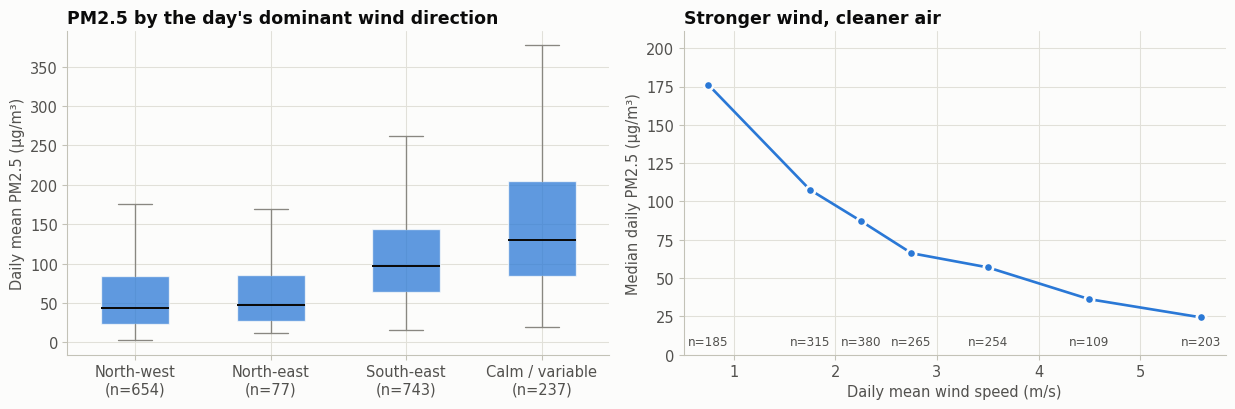

WS,"(0.0, 1.5]","(1.5, 2.0]","(2.0, 2.5]","(2.5, 3.0]","(3.0, 4.0]","(4.0, 5.0]","(5.0, 12.0]"
median,176.2,107.7,87.3,66.2,57.0,36.2,24.4
count,185.0,315.0,380.0,265.0,254.0,109.0,203.0


In [ ]:
# EDA 3: PM2.5 by dominant wind direction and by wind speed (Figure 3)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
order = ["NW", "NE", "SE", "cv"]
labels = {"NW": "North-west", "NE": "North-east", "SE": "South-east", "cv": "Calm / variable"}
data_by_dir = [daily.loc[(daily["main_wind"] == d) & daily["PM25"].notna(), "PM25"].values for d in order]
bp = ax.boxplot(data_by_dir, patch_artist=True, widths=0.5, showfliers=False,
                medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for box in bp["boxes"]:
    box.set_facecolor(BLUE); box.set_alpha(0.75); box.set_edgecolor(SURFACE)
ax.set_xticks(range(1, 5), [f"{labels[d]}\n(n={len(v)})" for d, v in zip(order, data_by_dir)])
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("PM2.5 by the day's dominant wind direction")

ax = axes[1]
bins = [0, 1.5, 2, 2.5, 3, 4, 5, 12]
ws_bin = pd.cut(daily["WS"], bins)
ws_stats = daily.groupby(ws_bin, observed=True)["PM25"].agg(["median", "count"])
centers = [(b.left + b.right) / 2 if b.right < 12 else 5.6 for b in ws_stats.index]
ax.plot(centers, ws_stats["median"], color=BLUE, marker="o", markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
for x, n in zip(centers, ws_stats["count"]):
    ax.text(x, 6, f"n={int(n)}", ha="center", fontsize=9, color=INK2)
ax.set_xlabel("Daily mean wind speed (m/s)")
ax.set_ylabel("Median daily PM2.5 (µg/m³)")
ax.set_title("Stronger wind, cleaner air")
ax.set_ylim(0, ws_stats["median"].max() * 1.2)
plt.tight_layout()
save_fig("03_wind_direction_speed")
plt.show()
ws_stats.round(1).T

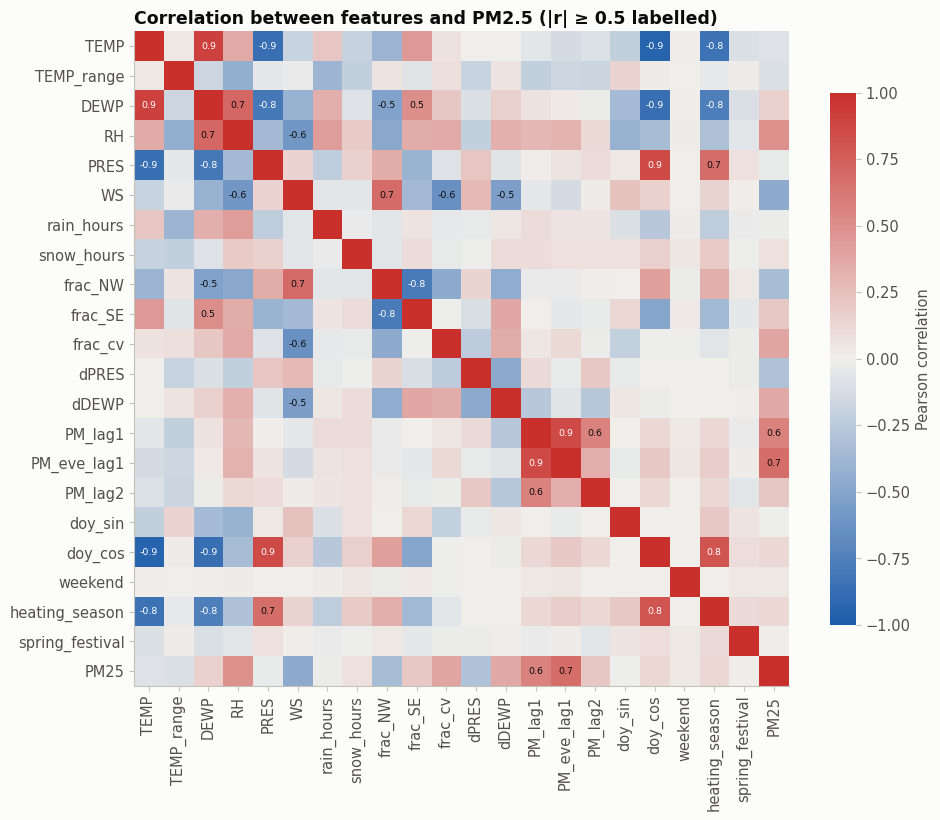

,WS,frac_NW,dPRES,TEMP_range,TEMP,PRES,rain_hours,doy_sin,spring_festival,weekend,snow_hours,doy_cos,heating_season,DEWP,frac_SE,PM_lag2,dDEWP,frac_cv,RH,PM_lag1,PM_eve_lag1
r with PM2.5,-0.46,-0.34,-0.3,-0.1,-0.08,-0.03,-0.02,-0.01,0.01,0.03,0.07,0.12,0.12,0.15,0.2,0.21,0.36,0.39,0.49,0.57,0.68


In [ ]:
# EDA 4: correlation matrix of features and PM2.5 (Figure 4) + correlation of each feature with PM2.5
corr = daily[FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        if abs(v) >= 0.5 and i != j:
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7,
                    color="#ffffff" if abs(v) > 0.75 else INK)
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Pearson correlation")
cbar.outline.set_visible(False)
ax.set_title("Correlation between features and PM2.5 (|r| ≥ 0.5 labelled)")
save_fig("04_correlation_matrix")
plt.show()
corr[TARGET].drop(TARGET).sort_values().round(2).to_frame("r with PM2.5").T

## 5.2 Unsupervised learning: daily weather regimes (K-means + PCA)

In [ ]:
# Screen the 13 weather features for clustering: mostly-zero features and strongly correlated pairs
CANDIDATES = WEATHER          # the 13 daily weather features
cand_days = daily.loc[daily.index.year <= 2013].dropna(subset=CANDIDATES + [TARGET])   # training years only

zero_share = (cand_days[CANDIDATES] == 0).mean()
print("Share of days equal to 0:", zero_share[zero_share > 0.5].round(3).to_dict())

# Correlation: strongly correlated pairs, and how much of DEWP is explained by TEMP and RH
corr_w = cand_days[CANDIDATES].corr()
pairs = [(a, b, round(float(corr_w.loc[a, b]), 2)) for i, a in enumerate(CANDIDATES)
         for b in CANDIDATES[i + 1:] if abs(corr_w.loc[a, b]) >= 0.7]
print("Pairs with |r| >= 0.7:", pairs)
dewp_fit = LinearRegression().fit(cand_days[["TEMP", "RH"]], cand_days["DEWP"])
print(f"R² of DEWP explained by TEMP and RH: {dewp_fit.score(cand_days[['TEMP', 'RH']], cand_days['DEWP']):.3f}")

Share of days equal to 0: {'rain_hours': 0.791, 'snow_hours': 0.962}
Pairs with |r| >= 0.7: [('TEMP', 'DEWP', 0.91), ('TEMP', 'PRES', -0.86), ('DEWP', 'RH', 0.71), ('DEWP', 'PRES', -0.8), ('frac_NW', 'frac_SE', -0.79)]
R² of DEWP explained by TEMP and RH: 0.992


In [ ]:
# Compare the chosen 9 clustering features with alternative feature sets at k = 4 (silhouette, PM2.5 contrast)
REGIME_FEATURES = ["TEMP", "RH", "PRES", "WS", "frac_NW", "frac_SE", "frac_cv", "rain_hours", "TEMP_range"]

def regime_summary(features, k=4):
    Zs = StandardScaler().fit_transform(cand_days[features])
    labels = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit_predict(Zs)
    pm = cand_days[TARGET].groupby(labels).mean()
    return {"silhouette": silhouette_score(Zs, labels), "cleanest regime PM2.5": pm.min(),
            "dirtiest regime PM2.5": pm.max(), "dirtiest / cleanest": pm.max() / pm.min()}

variants = {
    "Chosen 9": REGIME_FEATURES,
    "All 13 weather features": CANDIDATES,
    "9 + DEWP": REGIME_FEATURES + ["DEWP"],
    "9 + snow_hours": REGIME_FEATURES + ["snow_hours"],
    "9 + dPRES, dDEWP": REGIME_FEATURES + ["dPRES", "dDEWP"],
    "9 - TEMP_range": [f for f in REGIME_FEATURES if f != "TEMP_range"],
    "9 - rain_hours": [f for f in REGIME_FEATURES if f != "rain_hours"],
}
pd.DataFrame({name: regime_summary(f) for name, f in variants.items()}).T.round(2)

,silhouette,cleanest regime PM2.5,dirtiest regime PM2.5,dirtiest / cleanest
Chosen 9,0.25,46.61,124.70,2.68
All 13 weather features,0.23,44.28,141.98,3.21
9 + DEWP,0.26,46.45,124.94,2.69
9 + snow_hours,0.23,46.89,141.98,3.03
"9 + dPRES, dDEWP",0.21,43.78,134.74,3.08
9 - TEMP_range,0.28,47.01,128.38,2.73
9 - rain_hours,0.23,46.71,135.18,2.89


In [ ]:
# Choose the number of clusters: SSE (inertia) and silhouette score for k = 2–7
regime_days = daily.loc[daily.index.year <= 2013].dropna(subset=REGIME_FEATURES + [TARGET])
regime_scaler = StandardScaler().fit(regime_days[REGIME_FEATURES])
Z = regime_scaler.transform(regime_days[REGIME_FEATURES])

k_scores = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(Z)
    k_scores.append({"k": k, "SSE (inertia)": km.inertia_, "silhouette": silhouette_score(Z, km.labels_)})
pd.DataFrame(k_scores).set_index("k").round(3).T

k,2,3,4,5,6,7
SSE (inertia),8751.020,7273.455,6163.869,5544.110,5036.373,4713.958
silhouette,0.264,0.232,0.247,0.226,0.209,0.214


In [ ]:
# K-means with k = 4: name each weather regime from its average weather and count its days
K = 4   # silhouette is similar for k = 2-5; k = 4 gives nearly maximum silhouette value with quite lower SSE
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(Z)
regime_days = regime_days.assign(regime=kmeans.labels_)
profile = regime_days.groupby("regime")[REGIME_FEATURES + [TARGET]].mean()

names = {}
names[profile["WS"].idxmax()] = "Windy & dry (NW)"
names[profile.drop(index=list(names))["rain_hours"].idxmax()] = "Rainy & humid"
rest = profile.drop(index=list(names))
names[rest["TEMP"].idxmax()] = "Warm (summer, SE)"
names[rest["TEMP"].idxmin()] = "Cold & calm (winter)"
regime_days["regime_name"] = regime_days["regime"].map(names)
profile.index = profile.index.map(names)
profile["days"] = regime_days["regime_name"].value_counts()
profile.round(2)

,TEMP,RH,PRES,WS,frac_NW,frac_SE,frac_cv,rain_hours,TEMP_range,PM25,days
regime,,,,,,,,,,,
Rainy & humid,19.12,82.30,1009.84,2.50,0.28,0.37,0.21,8.38,5.33,105.46,126
Cold & calm (winter),3.35,55.37,1023.72,2.14,0.29,0.30,0.28,0.09,11.91,124.70,460
Windy & dry (NW),4.14,32.70,1022.80,5.47,0.76,0.06,0.07,0.11,10.47,46.61,283
"Warm (summer, SE)",22.92,61.78,1007.56,2.52,0.15,0.54,0.22,0.57,11.55,102.90,485


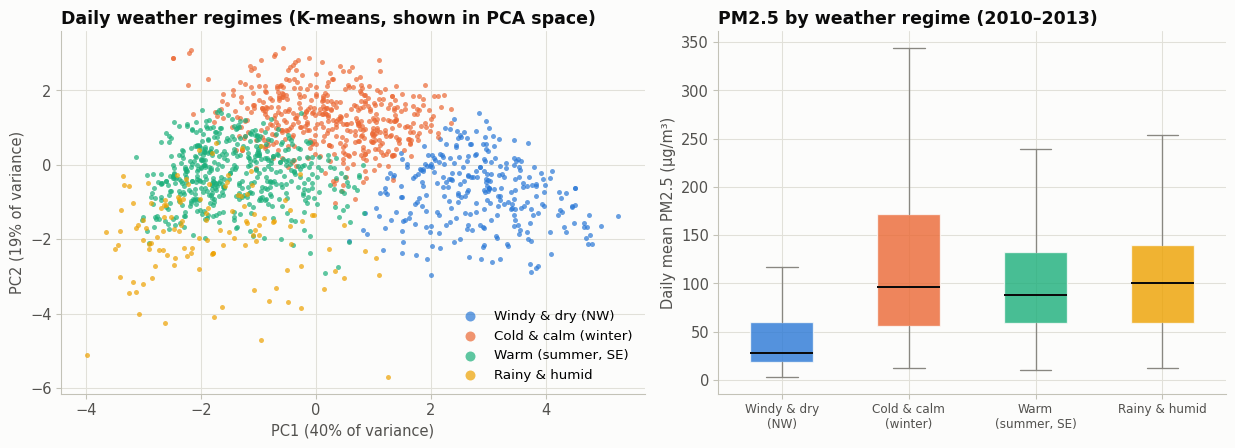

,count,mean,50%,75%
regime_name,,,,
Windy & dry (NW),283.0,46.6,28.3,60.1
Cold & calm (winter),460.0,124.7,96.3,171.8
"Warm (summer, SE)",485.0,102.9,88.2,132.4
Rainy & humid,126.0,105.5,100.8,139.8


In [ ]:
# Show the weather regimes in PCA space and PM2.5 in each regime (Figure 5)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z)
pcs = pca.transform(Z)
name_order = ["Windy & dry (NW)", "Cold & calm (winter)", "Warm (summer, SE)", "Rainy & humid"]
regime_colors = dict(zip(name_order, [BLUE, ORANGE, AQUA, YELLOW]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
for nm in name_order:
    m = (regime_days["regime_name"] == nm).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=14, color=regime_colors[nm], alpha=0.7, linewidths=0, label=nm)
ev = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")
ax.set_title("Daily weather regimes (K-means, shown in PCA space)")
ax.legend(loc="best", markerscale=2)

ax = axes[1]
data_reg = [regime_days.loc[regime_days["regime_name"] == nm, TARGET].values for nm in name_order]
bp = ax.boxplot(data_reg, patch_artist=True, widths=0.5, showfliers=False,
                medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for box, nm in zip(bp["boxes"], name_order):
    box.set_facecolor(regime_colors[nm]); box.set_alpha(0.8); box.set_edgecolor(SURFACE)
ax.set_xticks(range(1, 5), [nm.replace(" (", "\n(") for nm in name_order], fontsize=9)
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("PM2.5 by weather regime (2010–2013)")
plt.tight_layout()
save_fig("05_weather_regimes")
plt.show()
regime_days.groupby("regime_name")[TARGET].describe()[["count", "mean", "50%", "75%"]].loc[name_order].round(1)

# 6. Problem definition and train/test split

## 6.1 Selecting usable rows and splitting

In [ ]:
# Time-based split (train 2010–2013, test 2014) and the three year-by-year cross-validation folds
model_df = daily.dropna(subset=FEATURES + [TARGET]).copy()
train = model_df[model_df.index.year <= 2013]
test = model_df[model_df.index.year == 2014]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Rows usable for modelling: {len(model_df)} days")
print(f"Training: {len(train)} days ({train.index.min():%d %b %Y} – {train.index.max():%d %b %Y})")
print(f"Test:     {len(test)} days ({test.index.min():%d %b %Y} – {test.index.max():%d %b %Y})")

train_years = X_train.index.year
VAL_YEARS = (2011, 2012, 2013)
cv_folds = [(np.where(train_years < yr)[0], np.where(train_years == yr)[0]) for yr in VAL_YEARS]
pd.DataFrame([{"fold": i + 1,
               "train on": "2010" if yr == 2011 else f"2010–{yr - 1}",
               "validate on": yr, "train days": len(tr), "validation days": len(va)}
              for i, ((tr, va), yr) in enumerate(zip(cv_folds, VAL_YEARS))]).set_index("fold")

Rows usable for modelling: 1618 days
Training: 1276 days (04 Jan 2010 – 28 Dec 2013)
Test:     342 days (02 Jan 2014 – 31 Dec 2014)


,train on,validate on,train days,validation days
fold,,,,
1,2010,2011,308,291
2,2010–2011,2012,599,322
3,2010–2012,2013,921,355


## 6.2 Baseline: persistence forecast

In [ ]:
# Baseline: persistence forecast (tomorrow = today) evaluated on 2014
baseline = regression_metrics(y_test, test["PM_lag1"])
print("Persistence forecast on 2014:  " + "  ".join(f"{k} = {v:.3f}" for k, v in baseline.items()))

Persistence forecast on 2014:  R2 = 0.207  MAE = 51.593  RMSE = 73.114


# 7. Models and hyperparameter tuning

## 7.1 Continuous training and CV

In [ ]:
# Tune 9 models with GridSearchCV / RandomizedSearchCV on the year-by-year CV folds
def scaled(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

TREES = [100, 200, 300, 500, 800, 1200, 2000, 3000]
LEARNING_RATE = [0.003, 0.005, 0.01, 0.02, 0.03, 0.05, 0.1]
ROW_SAMPLE = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
COL_SAMPLE = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
L2_PENALTY = [0, 1, 3, 5, 10, 30, 100]

candidates = {
    "Linear Regression": (scaled(LinearRegression()), None, None),
    "Elastic Net": (scaled(ElasticNet(max_iter=100_000)),
                    {"model__alpha": [1e-4, 3e-4, 1e-3, 3e-3, 0.01, 0.03, 0.1, 0.3, 1, 3],
                     "model__l1_ratio": [0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]}, "grid"),
    "KNN": (scaled(KNeighborsRegressor()),
            {"model__n_neighbors": [3, 4, 5, 6, 7, 8, 10, 12, 15, 20, 30],
             "model__weights": ["uniform", "distance"], "model__metric": ["euclidean", "manhattan"]}, "grid"),
    "SVR (RBF)": (scaled(SVR(kernel="rbf")),
                  {"model__C": [1e3, 3e3, 1e4, 3e4, 1e5, 3e5, 1e6], "model__epsilon": [5, 10, 15],
                   "model__gamma": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]}, "grid"),
    "Decision Tree": (DecisionTreeRegressor(random_state=RANDOM_STATE),
                      {"max_depth": [2, 3, 4, 5, 6, 8, 10, 12, 15, None],
                       "min_samples_leaf": [1, 2, 5, 10, 15, 20, 30, 40, 60, 80]}, "grid"),
    "Random Forest": (RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=1),
                      {"max_depth": [8, 12, 16, None], "min_samples_leaf": [1, 2, 4, 8],
                       "max_features": [0.2, 0.33, 0.5, 0.7, 1.0]}, "grid"),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {"n_estimators": TREES, "learning_rate": LEARNING_RATE, "max_depth": [1, 2, 3, 4, 5, 6, 8],
                           "subsample": ROW_SAMPLE, "min_samples_leaf": [1, 3, 5, 10, 20, 40],
                           "max_features": [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]}, "random"),
    "XGBoost": (XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": TREES, "learning_rate": LEARNING_RATE, "max_depth": [1, 2, 3, 4, 5, 6, 8],
                 "min_child_weight": [1, 3, 5, 10, 20, 40], "subsample": ROW_SAMPLE,
                 "colsample_bytree": COL_SAMPLE, "reg_lambda": L2_PENALTY}, "random"),
    "LightGBM": (LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
                 {"n_estimators": TREES, "learning_rate": LEARNING_RATE, "num_leaves": [2, 3, 4, 7, 15, 31, 63],
                  "min_child_samples": [1, 2, 5, 10, 20, 40, 80], "subsample": ROW_SAMPLE,
                  "colsample_bytree": COL_SAMPLE, "reg_lambda": L2_PENALTY}, "random"),
}

SCORING = "neg_root_mean_squared_error"
N_ITER = 150
tuned, search_log = {}, {}
for name, (estimator, grid, kind) in candidates.items():
    t0 = time.time()
    if grid is None:
        scores = cross_val_score(estimator, X_train, y_train, cv=cv_folds, scoring=SCORING)
        best_model, best_params, fold_rmse = estimator.fit(X_train, y_train), {}, -scores
        n_settings = 1
    else:
        if kind == "grid":
            search = GridSearchCV(estimator, grid, cv=cv_folds, scoring=SCORING, n_jobs=-1)
        else:
            search = RandomizedSearchCV(estimator, grid, n_iter=N_ITER, cv=cv_folds, scoring=SCORING,
                                        n_jobs=-1, random_state=RANDOM_STATE)
        search.fit(X_train, y_train)            # refit=True: best setting re-trained on all of 2010-2013
        best_model, best_params = search.best_estimator_, search.best_params_
        fold_rmse = -np.array([search.cv_results_[f"split{k}_test_score"][search.best_index_]
                               for k in range(len(cv_folds))])
        n_settings = len(search.cv_results_["params"])
    tuned[name] = best_model
    search_log[name] = {"CV RMSE": fold_rmse.mean(), "CV RMSE std": fold_rmse.std(), "fold RMSE": fold_rmse,
                        "settings tested": n_settings,
                        "best parameters": {k.replace("model__", ""): v for k, v in best_params.items()},
                        "seconds": time.time() - t0}
    print(f"{name:18s} CV RMSE = {fold_rmse.mean():6.2f} ± {fold_rmse.std():5.2f} µg/m³")

Linear Regression  CV RMSE =  40.25 ±  3.51 µg/m³
Elastic Net        CV RMSE =  40.25 ±  3.51 µg/m³
KNN                CV RMSE =  43.10 ±  4.37 µg/m³
SVR (RBF)          CV RMSE =  34.13 ±  4.04 µg/m³
Decision Tree      CV RMSE =  45.74 ±  5.05 µg/m³
Random Forest      CV RMSE =  37.59 ±  3.26 µg/m³
Gradient Boosting  CV RMSE =  35.67 ±  2.48 µg/m³
XGBoost            CV RMSE =  35.96 ±  2.60 µg/m³
LightGBM           CV RMSE =  36.08 ±  2.03 µg/m³


In [ ]:
# Build and cross-validate the stacking ensemble, then list all 10 models by CV RMSE
# 10th model: stacking four strong learners of different families
stack = StackingRegressor(
    estimators=[("rf", tuned["Random Forest"]), ("xgb", tuned["XGBoost"]),
                ("lgbm", tuned["LightGBM"]), ("svr", tuned["SVR (RBF)"])],
    final_estimator=LinearRegression(positive=True),
    cv=KFold(n_splits=5), n_jobs=1)
t0 = time.time()
scores = cross_val_score(stack, X_train, y_train, cv=cv_folds, scoring=SCORING, n_jobs=-1)
stack.fit(X_train, y_train)
tuned["Stacking"] = stack
search_log["Stacking"] = {"CV RMSE": -scores.mean(), "CV RMSE std": scores.std(), "fold RMSE": -scores,
                          "settings tested": 1,
                          "best parameters": {"meta-learner weights": {k: round(float(w), 3) for k, w in
                                                zip(["rf", "xgb", "lgbm", "svr"], stack.final_estimator_.coef_)}},
                          "seconds": time.time() - t0}
print(f"Stacking           CV RMSE = {-scores.mean():6.2f} ± {scores.std():5.2f} µg/m³   ({time.time() - t0:5.1f} s)")
print("Meta-learner weights:", search_log["Stacking"]["best parameters"]["meta-learner weights"])

pd.DataFrame({name: {"CV RMSE": log["CV RMSE"], "best parameters": log["best parameters"]}
              for name, log in search_log.items()}).T.sort_values("CV RMSE")

Stacking           CV RMSE =  33.58 ±  3.26 µg/m³   (101.5 s)
Meta-learner weights: {'rf': 0.083, 'xgb': 0.0, 'lgbm': 0.443, 'svr': 0.527}


,CV RMSE,best parameters
Stacking,33.57931,"{'meta-learner weights': {'rf': 0.083, 'xgb': ..."
SVR (RBF),34.126443,"{'C': 300000.0, 'epsilon': 10, 'gamma': 0.0003}"
Gradient Boosting,35.668651,"{'subsample': 0.3, 'n_estimators': 3000, 'min_..."
XGBoost,35.960191,"{'subsample': 0.2, 'reg_lambda': 3, 'n_estimat..."
LightGBM,36.079105,"{'subsample': 0.2, 'reg_lambda': 0, 'num_leave..."
Random Forest,37.594569,"{'max_depth': 16, 'max_features': 0.7, 'min_sa..."
Linear Regression,40.251175,{}
Elastic Net,40.251432,"{'alpha': 0.0001, 'l1_ratio': 1.0}"
KNN,43.096957,"{'metric': 'manhattan', 'n_neighbors': 8, 'wei..."
Decision Tree,45.737046,"{'max_depth': 8, 'min_samples_leaf': 15}"


## 7.2 Are the search ranges wide enough?

In [ ]:
# Check that the search ranges are wide enough: is each best hyperparameter inside its searched range?
NATURAL_LIMITS = {"l1_ratio": (0, 1), "subsample": (None, 1.0), "colsample_bytree": (None, 1.0),
                  "max_features": (None, 1.0), "min_samples_leaf": (1, None), "min_child_samples": (1, None),
                  "min_child_weight": (1, None), "reg_lambda": (0, None), "num_leaves": (2, None),
                  "max_depth": (1, None), "n_neighbors": (1, None)}
TOLERANCE = 0.1   # µg/m³

def cv_rmse(model):
    return -cross_val_score(model, X_train, y_train, cv=cv_folds, scoring=SCORING, n_jobs=-1).mean()

def describe_range(values):
    numbers = sorted(v for v in values if isinstance(v, (int, float)) and not isinstance(v, bool))
    if not numbers:
        return ", ".join(map(str, values))
    text = f"{numbers[0]:g} – {numbers[-1]:g} ({len(numbers)} values)"
    return text + " + None (unlimited)" if None in values else text

range_rows = []
for name, (estimator, grid, kind) in candidates.items():
    if grid is None:
        continue
    model, model_cv = tuned[name], search_log[name]["CV RMSE"]
    for key, values in grid.items():
        param, best = key.replace("model__", ""), model.get_params()[key]
        numbers = sorted(v for v in values if isinstance(v, (int, float)) and not isinstance(v, bool))
        low_limit, high_limit = NATURAL_LIMITS.get(param, (None, None))
        check, verdict = "", "inside range"
        if isinstance(best, str):
            verdict = "categorical"
        elif best is None:
            verdict = "natural limit (unlimited)"
        elif (best == numbers[0] and best == low_limit) or (best == numbers[-1] and best == high_limit):
            verdict = "natural limit"
        elif best == numbers[-1] and None in values:
            verdict = "inside range (unlimited also tried)"
        elif best in (numbers[0], numbers[-1]):
            upper = best == numbers[-1]
            trial = clone(model)
            if param == "learning_rate":              # half (double) the rate needs twice (half) the trees
                factor = 2 if upper else 0.5
                trees = int(model.get_params()["n_estimators"] / factor)
                trial.set_params(**{key: best * factor, "n_estimators": trees})
                tried = f"{best * factor:g} with {trees} trees"
            else:
                value = best * 2 if upper else best / 2
                value = max(int(value), 1) if isinstance(best, (int, np.integer)) else value
                trial.set_params(**{key: value})
                tried = f"{value:g}"
            change = cv_rmse(trial) - model_cv
            check = f"{tried}: {change:+.2f}"
            verdict = "edge, extension does not help" if change > -TOLERANCE else "EXTEND THE RANGE"
        range_rows.append({"model": name, "hyperparameter": param, "searched": describe_range(values),
                           "best": best, "extension tried: change in CV RMSE": check,
                           "verdict": verdict})

range_check = pd.DataFrame(range_rows).set_index(["model", "hyperparameter"])
print(range_check["verdict"].value_counts().to_string())
range_check

verdict
inside range                           23
natural limit                           4
edge, extension does not help           3
categorical                             2
inside range (unlimited also tried)     1


searched       best extension tried: change in CV RMSE                              verdict
model             hyperparameter                                                                                                                            
Elastic Net       alpha                            0.0001 – 3 (10 values)     0.0001                       5e-05: -0.00        edge, extension does not help
                  l1_ratio                            0.05 – 1 (7 values)        1.0                                                           natural limit
KNN               n_neighbors                          3 – 30 (11 values)          8                                                            inside range
                  weights                               uniform, distance   distance                                                             categorical
                  metric                             euclidean, manhattan  manhattan                                                             categorical
SVR (RBF)         C                               1000 – 1e+06 (7 values)   300000.0                                                            inside range
                  epsilon                               5 – 15 (3 values)         10                                                            inside range
                  gamma                          0.0001 – 0.01 (5 values)     0.0003                                                            inside range
Decision Tree     max_depth          2 – 15 (9 values) + None (unlimited)          8                                                            inside range
                  min_samples_leaf                     1 – 80 (10 values)         15                                                            inside range
Random Forest     max_depth          8 – 16 (3 values) + None (unlimited)         16                                     inside range (unlimited also tried)
                  min_samples_leaf                       1 – 8 (4 values)          2                                                            inside range
                  max_features                         0.2 – 1 (5 values)        0.7                                                            inside range
Gradient Boosting n_estimators                      100 – 3000 (8 values)       3000                        6000: +0.12        edge, extension does not help
                  learning_rate                    0.003 – 0.1 (7 values)      0.003      0.0015 with 6000 trees: -0.03        edge, extension does not help
                  max_depth                              1 – 8 (7 values)          3                                                            inside range
                  subsample                           0.1 – 1 (10 values)        0.3                                                            inside range
                  min_samples_leaf                      1 – 40 (6 values)          3                                                            inside range
                  max_features                        0.05 – 1 (7 values)        0.5                                                            inside range
XGBoost           n_estimators                      100 – 3000 (8 values)        800                                                            inside range
                  learning_rate                    0.003 – 0.1 (7 values)       0.02                                                            inside range
                  max_depth                              1 – 8 (7 values)          2                                                            inside range
                  min_child_weight                      1 – 40 (6 values)          1                                                           natural limit
                  subsample                           0.1 – 1 (10 values)        0.2                                                        

## 7.3 Year-by-year validation results

In [ ]:
# Year-by-year validation RMSE of every model (validate on 2011, 2012, 2013)
fold_table = pd.DataFrame({name: log["fold RMSE"] for name, log in search_log.items()},
                          index=[f"validate {yr}" for yr in VAL_YEARS]).T
fold_table["mean"] = fold_table.mean(axis=1)
fold_table = fold_table.sort_values("mean")
first, second = fold_table.index[:2]
wins = int((fold_table.loc[first].iloc[:3] < fold_table.loc[second].iloc[:3]).sum())
print(f"{first} has a lower validation RMSE than {second} in {wins} of 3 years "
      f"(mean difference {fold_table.loc[second, 'mean'] - fold_table.loc[first, 'mean']:.2f} µg/m³)")
fold_table.round(2)

Stacking has a lower validation RMSE than SVR (RBF) in 2 of 3 years (mean difference 0.55 µg/m³)


,validate 2011,validate 2012,validate 2013,mean
Stacking,32.38,30.32,38.04,33.58
SVR (RBF),33.07,29.79,39.51,34.13
Gradient Boosting,34.22,33.64,39.15,35.67
XGBoost,35.02,33.36,39.51,35.96
LightGBM,34.87,34.43,38.94,36.08
Random Forest,37.78,33.52,41.49,37.59
Linear Regression,38.86,36.82,45.07,40.25
Elastic Net,38.86,36.82,45.07,40.25
KNN,45.17,37.01,47.11,43.10
Decision Tree,48.49,38.65,50.07,45.74


# 8. Model evaluation on the unseen test year (2014)

## 8.1 Evaluation

In [ ]:
# Test all models on 2014, select the best by CV RMSE
predictions = {"Persistence (baseline)": test["PM_lag1"].values}
rows = [{"Model": "Persistence (baseline)", "CV RMSE": np.nan,
         "Train R2": r2_score(y_train, train["PM_lag1"]), **baseline}]
for name, model in tuned.items():
    pred_train, pred_test = model.predict(X_train), model.predict(X_test)
    predictions[name] = pred_test
    rows.append({"Model": name, "CV RMSE": search_log[name]["CV RMSE"],
                 "Train R2": r2_score(y_train, pred_train), **regression_metrics(y_test, pred_test)})

results = pd.DataFrame(rows).set_index("Model")
results["Train–test R2 gap"] = results["Train R2"] - results["R2"]
results = results.sort_values("CV RMSE", na_position="last")
BEST = results["CV RMSE"].idxmin()
print(f"Selected model (lowest cross-validation RMSE): {BEST}")

results.to_csv(RESULTS_DIR / "model_comparison.csv", float_format="%.4f")
with open(RESULTS_DIR / "best_hyperparameters.json", "w") as f:
    json.dump({k: {p: (v.item() if hasattr(v, "item") else v) for p, v in log["best parameters"].items()}
               for k, log in search_log.items()}, f, indent=2, default=str)
results.round(3)

Selected model (lowest cross-validation RMSE): Stacking


,CV RMSE,Train R2,R2,MAE,RMSE,Train–test R2 gap
Model,,,,,,
Stacking,33.579,0.882,0.855,22.706,31.298,0.027
SVR (RBF),34.126,0.837,0.828,24.481,34.080,0.009
Gradient Boosting,35.669,0.895,0.843,23.505,32.539,0.052
XGBoost,35.960,0.866,0.841,23.812,32.764,0.025
LightGBM,36.079,0.882,0.837,24.156,33.101,0.044
Random Forest,37.595,0.957,0.837,24.391,33.116,0.120
Linear Regression,40.251,0.737,0.770,29.375,39.369,-0.033
Elastic Net,40.251,0.737,0.770,29.375,39.369,-0.033
KNN,43.097,1.000,0.767,28.608,39.606,0.233


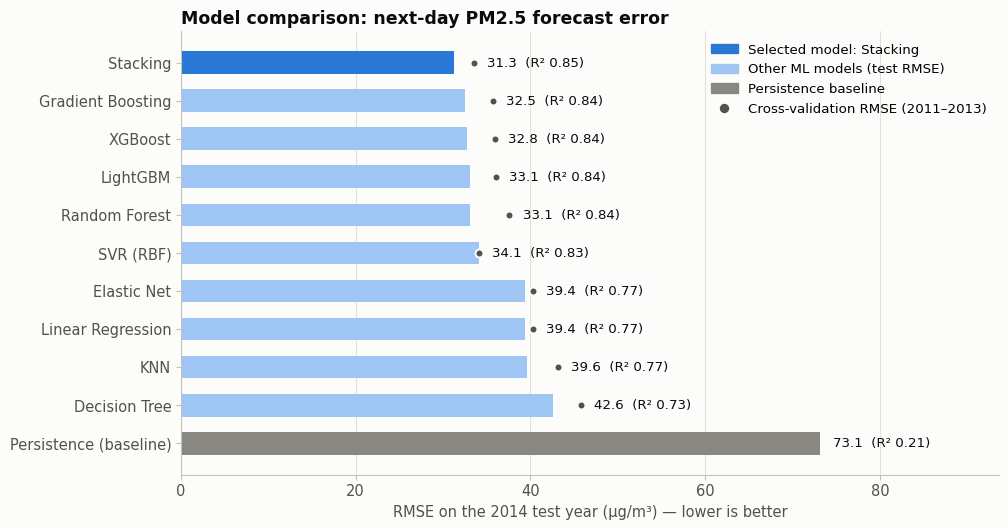

In [ ]:
# Model comparison chart: test RMSE (bars) and CV RMSE (dots) of all models (Figure 6)
order = results.sort_values("RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))
ypos = np.arange(len(order))
colors = [MUTED if n.startswith("Persistence") else (BLUE if n == BEST else "#9ec5f4") for n in order.index]
ax.barh(ypos, order["RMSE"], color=colors, height=0.6)
ax.scatter(order["CV RMSE"], ypos, color=INK2, s=36, zorder=3, edgecolors=SURFACE, linewidths=1.5)
for y, (rmse, cv, r2) in enumerate(zip(order["RMSE"], order["CV RMSE"], order["R2"])):
    x_label = np.nanmax([rmse, cv]) + 1.5
    ax.text(x_label, y, f"{rmse:.1f}  (R² {r2:.2f})", va="center", fontsize=10, color=INK)
ax.set_yticks(ypos, order.index)
ax.set_xlabel("RMSE on the 2014 test year (µg/m³) — lower is better")
ax.set_title("Model comparison: next-day PM2.5 forecast error")
ax.set_xlim(0, order["RMSE"].max() * 1.28)
ax.legend(handles=[mpl.patches.Patch(color=BLUE, label=f"Selected model: {BEST}"),
                   mpl.patches.Patch(color="#9ec5f4", label="Other ML models (test RMSE)"),
                   mpl.patches.Patch(color=MUTED, label="Persistence baseline"),
                   mpl.lines.Line2D([], [], marker="o", color=INK2, linestyle="", label="Cross-validation RMSE (2011–2013)")],
          loc="upper right")
ax.grid(axis="y", visible=False)
save_fig("06_model_comparison")
plt.show()

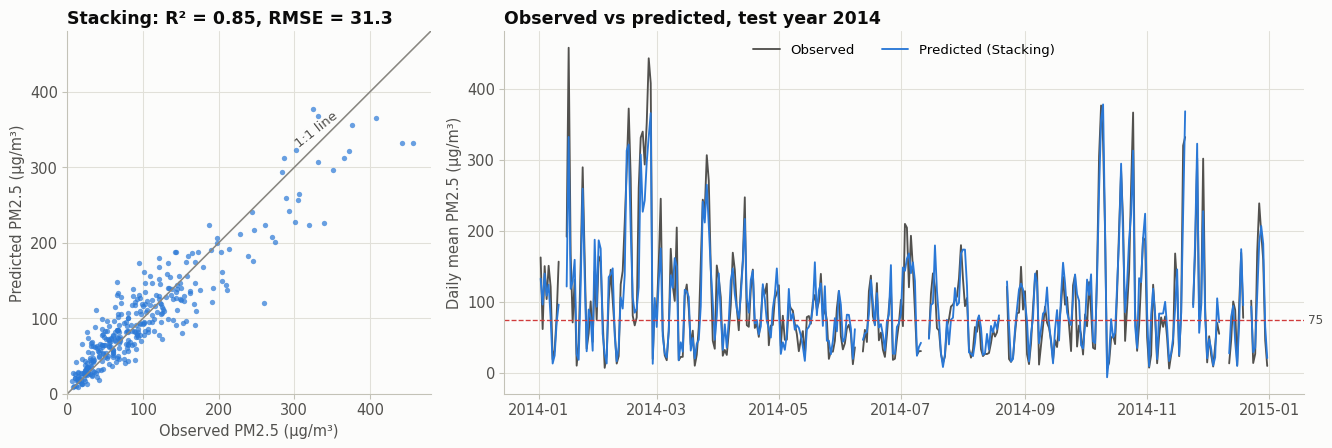

PM25,<35,35–75,75–150,150–250,>250
days,73.0,91.0,116.0,38.0,24.0
mean_error,-9.3,-13.8,-1.2,27.4,45.9
MAE,11.7,20.5,20.2,34.4,58.1


In [ ]:
# Best model: observed vs predicted PM2.5 in 2014 (Figure 7) and forecast error by pollution level
best_pred = pd.Series(predictions[BEST], index=y_test.index)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 2.2]})
ax = axes[0]
lim = max(y_test.max(), best_pred.max()) * 1.05
ax.scatter(y_test, best_pred, s=16, color=BLUE, alpha=0.7, linewidths=0)
ax.plot([0, lim], [0, lim], color=MUTED, linewidth=1.2)
ax.text(lim * 0.62, lim * 0.68, "1:1 line", color=INK2, fontsize=10, rotation=38)
m = regression_metrics(y_test, best_pred)
ax.set_title(f"{BEST}: R² = {m['R2']:.2f}, RMSE = {m['RMSE']:.1f}")
ax.set_xlabel("Observed PM2.5 (µg/m³)"); ax.set_ylabel("Predicted PM2.5 (µg/m³)")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)

ax = axes[1]
days_2014 = pd.date_range("2014-01-01", "2014-12-31", freq="D")          # missing days appear as gaps
ax.plot(days_2014, y_test.reindex(days_2014).values, color=INK2, linewidth=1.4, label="Observed")
ax.plot(days_2014, best_pred.reindex(days_2014).values, color=BLUE, linewidth=1.4, label=f"Predicted ({BEST})")
ax.axhline(75, color=CRITICAL, linewidth=1, linestyle="--")
ax.text(1.005, 75, "75", transform=ax.get_yaxis_transform(), color=INK2, fontsize=9, va="center")
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("Observed vs predicted, test year 2014")
ax.legend(loc="upper center", ncol=2)
plt.tight_layout()
save_fig("07_best_model_predictions")
plt.show()

residual = y_test - best_pred
bands = pd.cut(y_test, [0, 35, 75, 150, 250, 600], labels=["<35", "35–75", "75–150", "150–250", ">250"])
residual.groupby(bands, observed=True).agg(days="count", mean_error="mean", MAE=lambda r: r.abs().mean()).round(1).T

## 8.2 From regression to a health alert (classification view)

In [ ]:
# Health alert (> 75 µg/m³): precision and recall of the forecasts + high-recall threshold chosen on validation
THRESHOLD = 75
actual_alert = (y_test.values > THRESHOLD).astype(int)

def alert_scores(pred, cut):
    flag = (np.asarray(pred) > cut).astype(int)
    return {"alert if forecast >": cut, "precision": precision_score(actual_alert, flag),
            "recall": recall_score(actual_alert, flag), "F1": f1_score(actual_alert, flag),
            "accuracy": (flag == actual_alert).mean(),
            "missed polluted days (FN)": int(((flag == 0) & (actual_alert == 1)).sum()),
            "false alarms (FP)": int(((flag == 1) & (actual_alert == 0)).sum())}

alert_table = pd.DataFrame([{"forecast": "Persistence", **alert_scores(predictions["Persistence (baseline)"], THRESHOLD)},
                            {"forecast": BEST, **alert_scores(best_pred, THRESHOLD)}]).set_index("forecast")
sweep = pd.DataFrame([alert_scores(best_pred, c) for c in range(40, 111, 5)]).set_index("alert if forecast >")
val_pred, val_true = [], []
for tr, va in cv_folds:
    fold_model = clone(tuned[BEST]).fit(X_train.iloc[tr], y_train.iloc[tr])
    val_pred.append(fold_model.predict(X_train.iloc[va]))
    val_true.append(y_train.iloc[va].values)
val_pred, val_true = np.concatenate(val_pred), np.concatenate(val_true)
val_alert = (val_true > THRESHOLD).astype(int)
val_recall = {c: recall_score(val_alert, (val_pred > c).astype(int)) for c in range(40, 111, 5)}
high_recall_cut = max(c for c, r in val_recall.items() if r >= 0.95)   # highest cut with >= 95 % recall in validation
print(f"High-recall threshold chosen on 2011–2013 validation predictions: {high_recall_cut} µg/m³ "
      f"(validation recall {val_recall[high_recall_cut]:.3f})")
alert_table.loc[f"{BEST}, high-recall setting chosen on validation (alert if forecast > {high_recall_cut})"] = alert_scores(best_pred, high_recall_cut)
print(f"Polluted days (> {THRESHOLD} µg/m³) in 2014: {actual_alert.sum()} of {len(actual_alert)}")
alert_table.round(3)

High-recall threshold chosen on 2011–2013 validation predictions: 70 µg/m³ (validation recall 0.957)
Polluted days (> 75 µg/m³) in 2014: 178 of 342


,alert if forecast >,precision,recall,F1,accuracy,missed polluted days (FN),false alarms (FP)
forecast,,,,,,,
Persistence,75,0.701,0.697,0.699,0.687,54,53
Stacking,75,0.835,0.910,0.871,0.860,16,32
"Stacking, high-recall setting chosen on validation (alert if forecast > 70)",70,0.797,0.927,0.857,0.839,13,42


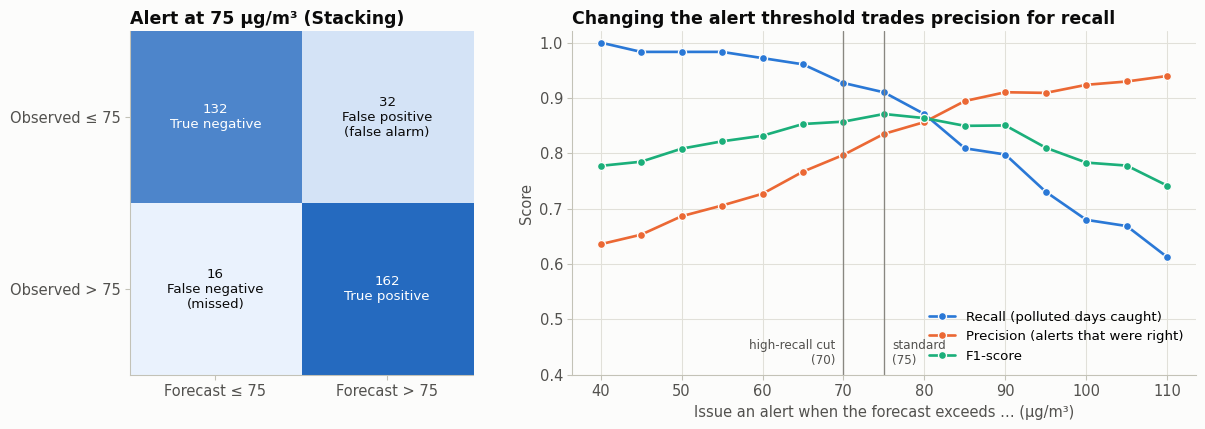

In [ ]:
# Alert charts: confusion matrix at 75 µg/m³ and scores for different alert thresholds (Figure 8)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
cm = confusion_matrix(actual_alert, (best_pred.values > THRESHOLD).astype(int))
ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("b", ["#eaf2fd", "#256abf"]))
cell_names = [["True negative", "False positive\n(false alarm)"], ["False negative\n(missed)", "True positive"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n{cell_names[i][j]}", ha="center", va="center", fontsize=10,
                color="#ffffff" if cm[i, j] > cm.max() * 0.6 else INK)
ax.set_xticks([0, 1], ["Forecast ≤ 75", "Forecast > 75"]); ax.set_yticks([0, 1], ["Observed ≤ 75", "Observed > 75"])
ax.grid(False)
ax.set_title(f"Alert at 75 µg/m³ ({BEST})")

ax = axes[1]
ax.plot(sweep.index, sweep["recall"], color=BLUE, marker="o", markersize=6, markeredgecolor=SURFACE, label="Recall (polluted days caught)")
ax.plot(sweep.index, sweep["precision"], color=ORANGE, marker="o", markersize=6, markeredgecolor=SURFACE, label="Precision (alerts that were right)")
ax.plot(sweep.index, sweep["F1"], color=AQUA, marker="o", markersize=6, markeredgecolor=SURFACE, label="F1-score")
ax.axvline(THRESHOLD, color=MUTED, linewidth=1)
ax.text(THRESHOLD + 1, 0.42, "standard\n(75)", fontsize=9, color=INK2, ha="left")
ax.axvline(high_recall_cut, color=MUTED, linewidth=1)
ax.text(high_recall_cut - 1, 0.42, f"high-recall cut\n({high_recall_cut})", fontsize=9, color=INK2, ha="right")
ax.set_xlabel("Issue an alert when the forecast exceeds … (µg/m³)")
ax.set_ylabel("Score"); ax.set_ylim(0.4, 1.02)
ax.set_title("Changing the alert threshold trades precision for recall")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("08_health_alert_evaluation")
plt.show()

# 9. Which information matters? Persistence vs weather

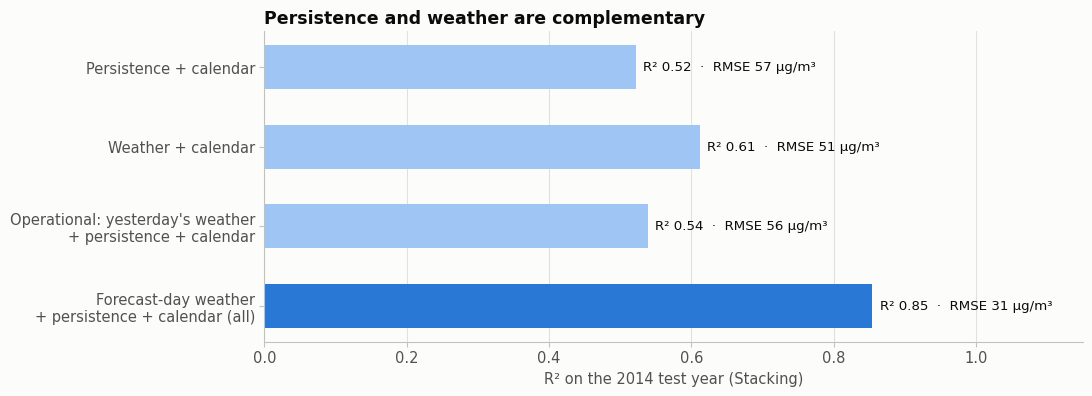

,features,R2,MAE,RMSE
feature group,,,,
Persistence + calendar,8,0.522,41.175,56.759
Weather + calendar,18,0.612,35.273,51.156
Operational: yesterday's weather\n+ persistence + calendar,21,0.540,40.133,55.700
Forecast-day weather\n+ persistence + calendar (all),21,0.855,22.706,31.298


In [ ]:
# Which information matters? Retrain the best model (stacking) on different feature groups and compare R² (Figure 9)
from sklearn.base import clone
for c in WEATHER:
    model_df[f"{c}_yesterday"] = daily[c].shift(1).reindex(model_df.index)
YESTERDAY_WEATHER = [f"{c}_yesterday" for c in WEATHER]
train_ext, test_ext = model_df.loc[train.index], model_df.loc[test.index]

feature_groups = {
    "Persistence + calendar": PERSISTENCE + CALENDAR,
    "Weather + calendar": WEATHER + CALENDAR,
    "Operational: yesterday's weather\n+ persistence + calendar": YESTERDAY_WEATHER + PERSISTENCE + CALENDAR,
    "Forecast-day weather\n+ persistence + calendar (all)": FEATURES,
}
group_rows = []
for label, cols in feature_groups.items():
    m = clone(tuned[BEST]).fit(train_ext[cols], y_train)
    group_rows.append({"feature group": label, "features": len(cols), **regression_metrics(y_test, m.predict(test_ext[cols]))})
groups = pd.DataFrame(group_rows).set_index("feature group")

fig, ax = plt.subplots(figsize=(11, 4.2))
ypos = np.arange(len(groups))[::-1]
ax.barh(ypos, groups["R2"], color=[BLUE if i == len(groups) - 1 else "#9ec5f4" for i in range(len(groups))], height=0.55)
for y, (r2, rmse) in zip(ypos, zip(groups["R2"], groups["RMSE"])):
    ax.text(r2 + 0.01, y, f"R² {r2:.2f}  ·  RMSE {rmse:.0f} µg/m³", va="center", fontsize=10, color=INK)
ax.set_yticks(ypos, groups.index)
ax.set_xlim(0, 1.15); ax.set_xlabel(f"R² on the 2014 test year ({BEST})")
ax.set_title("Persistence and weather are complementary")
ax.grid(axis="y", visible=False)
save_fig("09_feature_group_comparison")
plt.show()
groups.round(3)

# 10. Explainable machine learning: why does the model predict what it predicts?

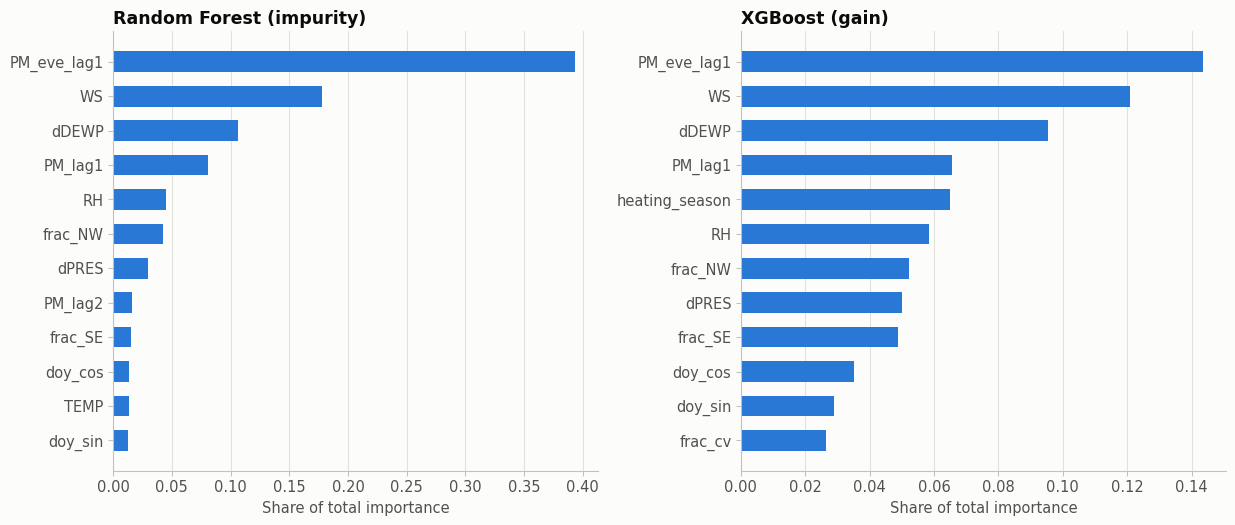

In [ ]:
# Built-in feature importance of Random Forest and XGBoost (Figure 10)
imp = pd.DataFrame({"Random Forest (impurity)": tuned["Random Forest"].feature_importances_,
                    "XGBoost (gain)": tuned["XGBoost"].feature_importances_}, index=FEATURES)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, col in zip(axes, imp.columns):
    s = imp[col].sort_values().tail(12)
    ax.barh(s.index, s.values, color=BLUE, height=0.6)
    ax.set_title(col); ax.set_xlabel("Share of total importance")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig("10_builtin_feature_importance")
plt.show()

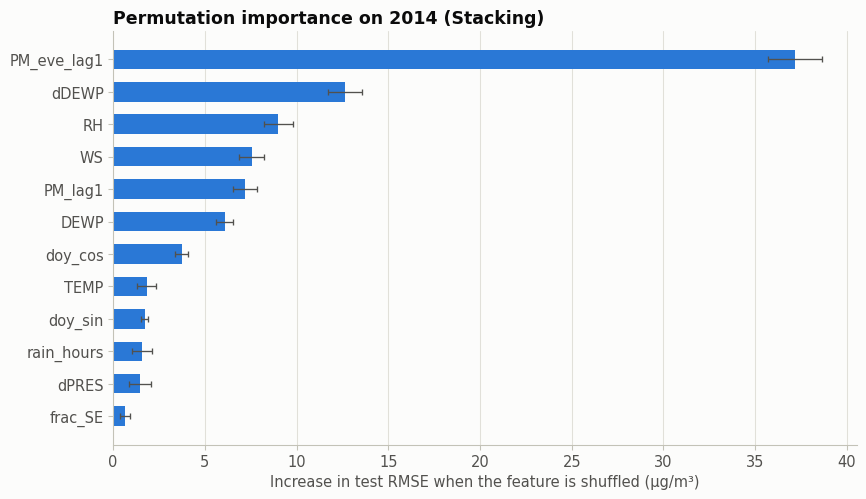

,PM_eve_lag1,dDEWP,RH,WS,PM_lag1,DEWP,doy_cos,TEMP,doy_sin,rain_hours
mean,37.16,12.65,9.01,7.55,7.18,6.07,3.73,1.82,1.71,1.58
std,1.47,0.92,0.77,0.68,0.64,0.45,0.37,0.51,0.21,0.54


In [ ]:
# Permutation importance of the best model (stacking) on the 2014 test set (Figure 11)
perm = permutation_importance(tuned[BEST], X_test, y_test, scoring=SCORING, n_repeats=20,
                              random_state=RANDOM_STATE, n_jobs=1)
perm_df = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=FEATURES).sort_values("mean")
top_perm = perm_df.tail(12)
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.barh(top_perm.index, top_perm["mean"], xerr=top_perm["std"], color=BLUE, height=0.6,
        error_kw=dict(ecolor=INK2, lw=1, capsize=2))
ax.set_xlabel("Increase in test RMSE when the feature is shuffled (µg/m³)")
ax.set_title(f"Permutation importance on 2014 ({BEST})")
ax.grid(axis="y", visible=False)
save_fig("11_permutation_importance")
plt.show()
perm_df.sort_values("mean", ascending=False).head(10).round(2).T

In [ ]:
# SHAP values of the stacking model (PermutationExplainer, all training days as background)
background = shap.maskers.Independent(X_train, max_samples=len(X_train))

stack_predict = lambda X: tuned[BEST].predict(pd.DataFrame(X, columns=FEATURES))
MAX_EVALS = 2 * len(FEATURES) + 1   # one random order of the 21 features per day, run forward and backward
explanation = shap.PermutationExplainer(stack_predict, background, seed=RANDOM_STATE)(X_test, max_evals=MAX_EVALS)

shap_values = pd.DataFrame(explanation.values, index=X_test.index, columns=FEATURES)
base_value = float(explanation.base_values[0])
additivity_error = np.abs(base_value + shap_values.sum(axis=1) - best_pred).max()
print(f"shap {shap.__version__} | {BEST}: base value = average forecast over the training days = {base_value:.1f} µg/m³ | "
      f"additivity check, max error: {additivity_error:.4f} µg/m³")

mean_abs_shap = shap_values.abs().mean().sort_values(ascending=False)
mean_abs_shap.round(2).to_frame("mean |SHAP| (µg/m³)").T

PermutationExplainer explainer: 343it [48:25,  8.52s/it]

shap 0.54.1 | Stacking: base value = average forecast over the training days = 98.7 µg/m³ | additivity check, max error: 0.0005 µg/m³


,PM_eve_lag1,dDEWP,RH,DEWP,WS,TEMP,PM_lag1,doy_cos,dPRES,frac_NW,doy_sin,TEMP_range,frac_SE,rain_hours,PRES,frac_cv,PM_lag2,heating_season,snow_hours,weekend,spring_festival
mean |SHAP| (µg/m³),29.68,15.04,15.04,11.02,10.37,9.88,7.89,7.24,6.14,4.93,4.42,3.7,3.65,3.24,2.76,1.73,1.72,0.65,0.64,0.43,0.14


In [ ]:
# Reliability check of the SHAP values: repeat with other random orders + compare top-5 drivers with other methods
repeat = shap.PermutationExplainer(stack_predict, background, seed=1)(X_test.iloc[::12], max_evals=MAX_EVALS)
change = np.abs(repeat.values - shap_values.iloc[::12].values)
print(f"Repeated with other feature orders ({len(change)} days): SHAP values change by {change.mean():.2f} µg/m³ on average, "
      f"95 % of them by less than {np.percentile(change, 95):.2f} µg/m³")

ranks = pd.DataFrame({f"{BEST}: SHAP": mean_abs_shap.index[:5],
                      f"{BEST}: permutation importance": perm_df["mean"].sort_values(ascending=False).index[:5]},
                     index=range(1, 6))
for name in ["XGBoost", "Random Forest"]:
    tree_shap = shap.TreeExplainer(tuned[name])(X_test).values
    ranks[f"{name}: TreeSHAP"] = pd.Series(np.abs(tree_shap).mean(axis=0), index=FEATURES).sort_values(ascending=False).index[:5]
for col in ranks.columns[1:]:
    print(f"{col}: {len(set(ranks[col]) & set(ranks.iloc[:, 0]))} of its top 5 are also in the top 5 of {BEST} SHAP")
ranks

PermutationExplainer explainer: 30it [04:04,  8.72s/it]


Repeated with other feature orders (29 days): SHAP values change by 0.09 µg/m³ on average, 95 % of them by less than 0.31 µg/m³
Stacking: permutation importance: 4 of its top 5 are also in the top 5 of Stacking SHAP
XGBoost: TreeSHAP: 3 of its top 5 are also in the top 5 of Stacking SHAP
Random Forest: TreeSHAP: 3 of its top 5 are also in the top 5 of Stacking SHAP


,Stacking: SHAP,Stacking: permutation importance,XGBoost: TreeSHAP,Random Forest: TreeSHAP
1,PM_eve_lag1,PM_eve_lag1,PM_eve_lag1,PM_eve_lag1
2,dDEWP,dDEWP,WS,WS
3,RH,RH,dDEWP,dDEWP
4,DEWP,WS,PM_lag1,frac_NW
5,WS,PM_lag1,dPRES,PM_lag1


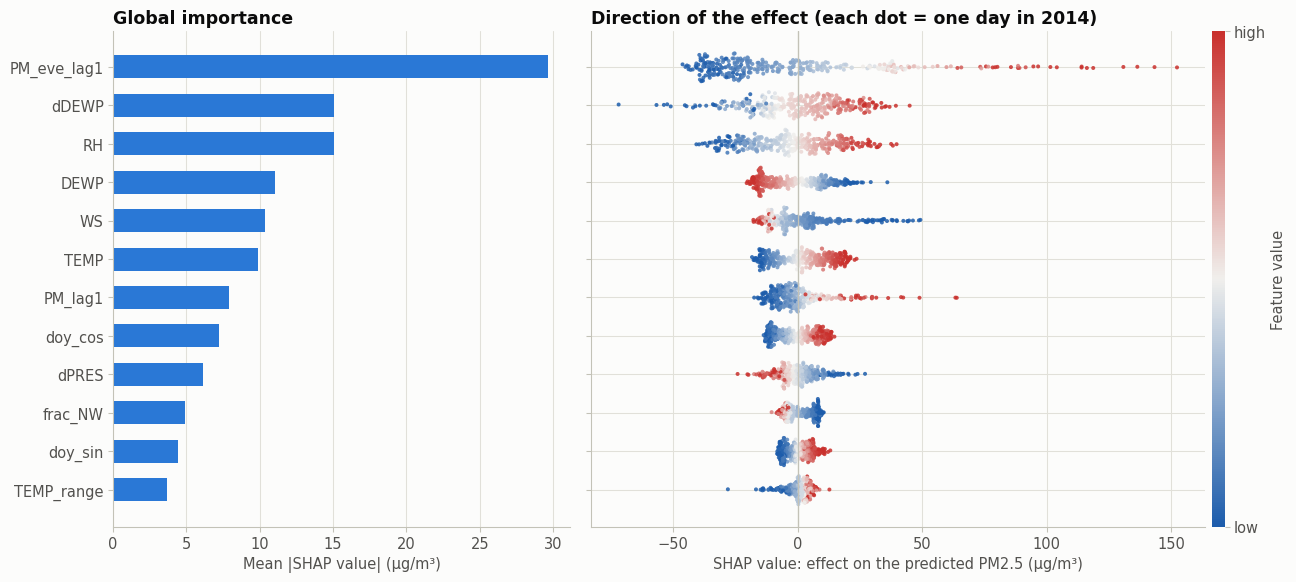

In [ ]:
# SHAP summary: global importance (bars) and direction of each feature's effect (beeswarm) (Figure 12)
def swarm_offsets(values, width=0.38, nbins=60, seed=0):
    """Vertical jitter proportional to local density, so the cloud of points looks like a beeswarm."""
    rng = np.random.default_rng(seed)
    edges = np.linspace(values.min(), values.max() + 1e-9, nbins + 1)
    idx = np.clip(np.digitize(values, edges) - 1, 0, nbins - 1)
    counts = np.bincount(idx, minlength=nbins)
    spread = width * counts[idx] / counts.max()
    return rng.uniform(-1, 1, len(values)) * spread

top = mean_abs_shap.index[:12][::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1, 1.6]}, sharey=True)
ax = axes[0]
ax.barh(range(len(top)), mean_abs_shap[top], color=BLUE, height=0.6)
ax.set_yticks(range(len(top)), top)
ax.set_xlabel("Mean |SHAP value| (µg/m³)")
ax.set_title("Global importance")
ax.grid(axis="y", visible=False)

ax = axes[1]
for i, feat in enumerate(top):
    vals = shap_values[feat].values
    fv = X_test[feat].values.astype(float)
    lo, hi = np.nanpercentile(fv, [5, 95])
    colour = np.clip((fv - lo) / (hi - lo if hi > lo else 1), 0, 1)
    ax.scatter(vals, i + swarm_offsets(vals, seed=i), c=colour, cmap=DIVERGING, s=9, alpha=0.85, linewidths=0)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlabel("SHAP value: effect on the predicted PM2.5 (µg/m³)")
ax.set_title("Direction of the effect (each dot = one day in 2014)")
sm = mpl.cm.ScalarMappable(cmap=DIVERGING); sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.01, aspect=40)
cbar.set_ticks([0, 1], labels=["low", "high"]); cbar.set_label("Feature value"); cbar.outline.set_visible(False)
plt.tight_layout()
save_fig("12_shap_summary")
plt.show()

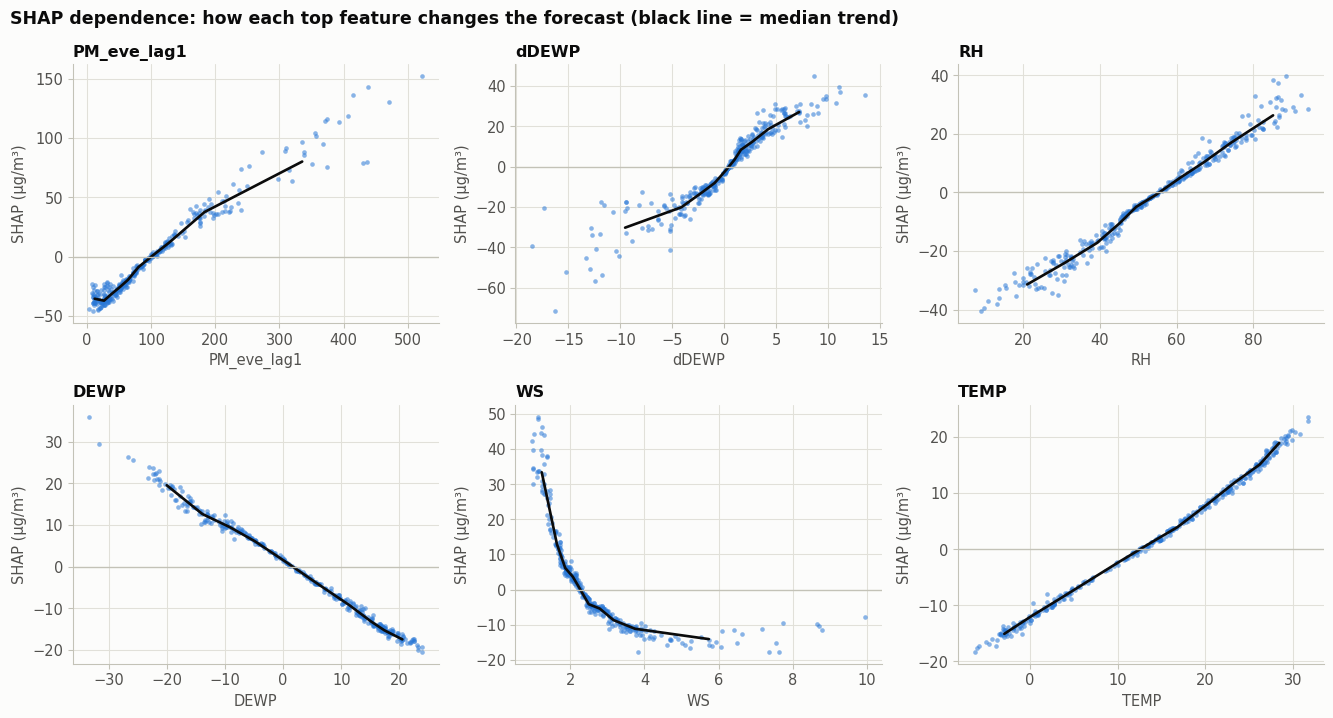

In [ ]:
# SHAP dependence plots: how the 6 most important features change the forecast (Figure 13)
DEPENDENCE = list(mean_abs_shap.index[:6])
fig, axes = plt.subplots(2, 3, figsize=(14, 7.6))
for ax, feat in zip(axes.ravel(), DEPENDENCE):
    x, s = X_test[feat], shap_values[feat]
    ax.scatter(x, s, s=12, color=BLUE, alpha=0.55, linewidths=0)
    if x.nunique() > 10:
        bins = pd.qcut(x, 10, duplicates="drop")
        trend = s.groupby(bins, observed=True).median()
        centers = x.groupby(bins, observed=True).median()
        ax.plot(centers, trend, color=INK, linewidth=2)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_xlabel(feat); ax.set_ylabel("SHAP (µg/m³)")
    ax.set_title(feat, fontsize=12)
fig.suptitle("SHAP dependence: how each top feature changes the forecast (black line = median trend)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
save_fig("13_shap_dependence")
plt.show()

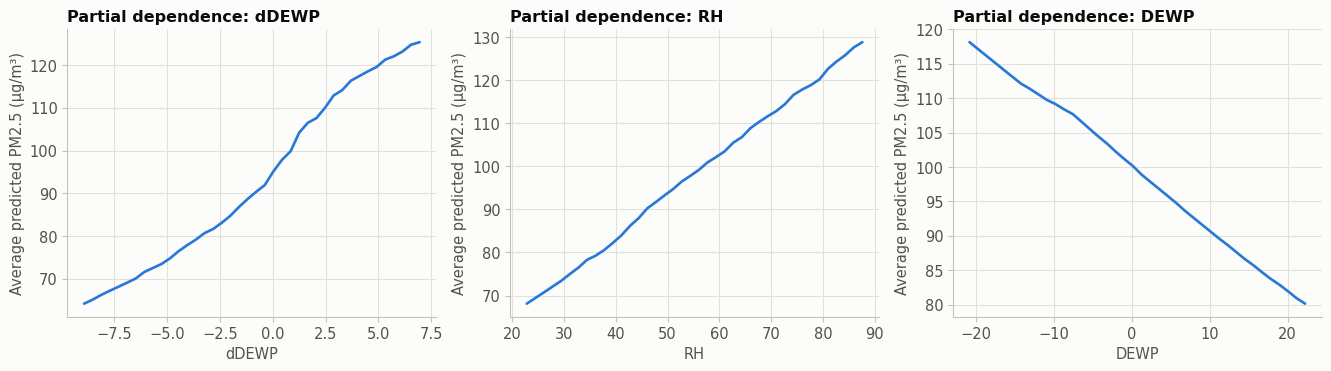

In [ ]:
# Partial dependence of the stacking forecast on the 3 most important weather features (Figure 14)
PDP_FEATURES = [f for f in mean_abs_shap.index if f in WEATHER][:3]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feat in zip(axes, PDP_FEATURES):
    pdp = partial_dependence(tuned[BEST], X_train, [feat], kind="average", grid_resolution=40)
    grid = pdp["grid_values"][0] if "grid_values" in pdp else pdp["values"][0]
    ax.plot(grid, pdp["average"][0], color=BLUE)
    ax.set_xlabel(feat); ax.set_ylabel("Average predicted PM2.5 (µg/m³)")
    ax.set_title(f"Partial dependence: {feat}", fontsize=12)
plt.tight_layout()
save_fig("14_partial_dependence")
plt.show()

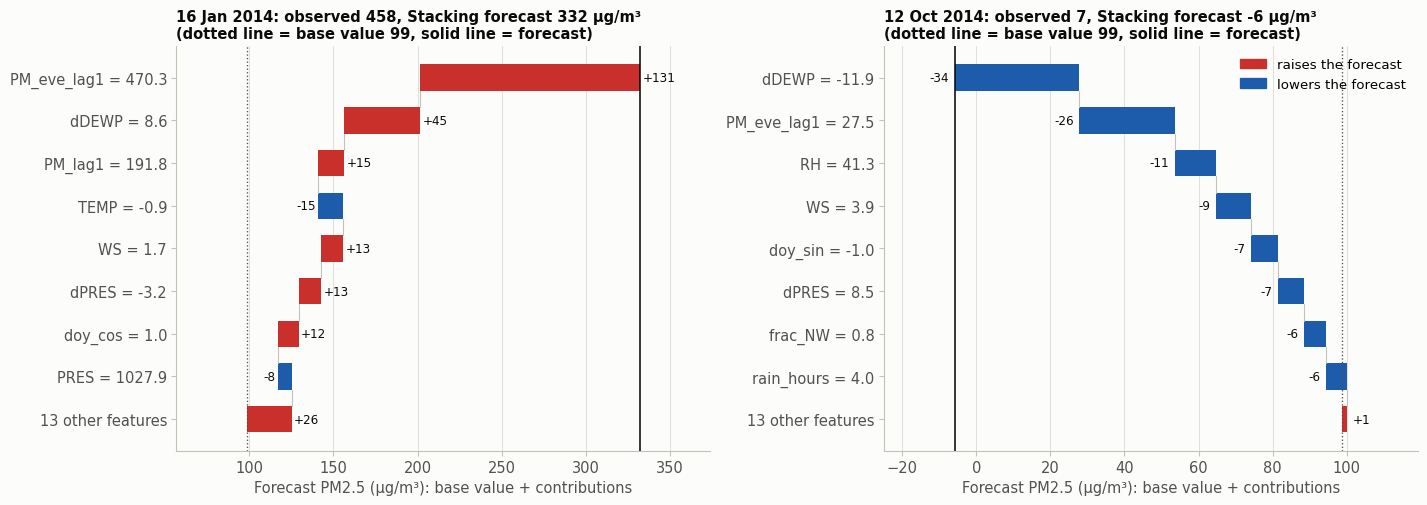

Haze day: 16 Jan 2014 | clean-up day after a polluted day: 12 Oct 2014


In [ ]:
# SHAP waterfall plots for two days: the worst haze day and the sharpest clean-up day (Figure 15)
def waterfall_day(ax, date, n=8):
    """SHAP waterfall (as in Lab 9): start at the base value, add one feature's contribution per row, end at the forecast."""
    sv = shap_values.loc[date]
    top_feats = list(sv.abs().sort_values(ascending=False).index[:n])
    steps = [(f"{f} = {X_test.loc[date, f]:.1f}", sv[f]) for f in top_feats]
    steps.append((f"{len(FEATURES) - n} other features", sv.drop(top_feats).sum()))
    steps = steps[::-1]          # drawn bottom-up: 'other features' at the bottom, the largest contribution at the top
    forecast = base_value + sv.sum()
    start = base_value + np.cumsum([0] + [v for _, v in steps[:-1]])
    for y, ((label, v), s) in enumerate(zip(steps, start)):
        colour = "#c9302c" if v > 0 else "#1c5cab"
        ax.barh(y, v, left=s, color=colour, height=0.62)
        ax.text(s + v + (1.5 if v >= 0 else -1.5), y, f"{v:+.0f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=9, color=INK)
        if y < len(steps) - 1:   # thin connector to the next step
            ax.plot([s + v, s + v], [y + 0.31, y + 0.69], color=AXIS, linewidth=0.8)
    ax.set_yticks(range(len(steps)), [label for label, _ in steps])
    ax.axvline(base_value, color=INK2, linewidth=1, linestyle=":")
    ax.axvline(forecast, color=INK, linewidth=1.2)
    ax.set_xlabel("Forecast PM2.5 (µg/m³): base value + contributions")
    ax.set_title(f"{date:%d %b %Y}: observed {y_test[date]:.0f}, {BEST} forecast {forecast:.0f} µg/m³\n"
                 f"(dotted line = base value {base_value:.0f}, solid line = forecast)", fontsize=11)
    ax.grid(axis="y", visible=False)
    lo = min(base_value, forecast, *(start + np.array([v for _, v in steps])), *start)
    hi = max(base_value, forecast, *(start + np.array([v for _, v in steps])), *start)
    pad = (hi - lo) * 0.18
    ax.set_xlim(lo - pad, hi + pad)

haze_day = y_test.idxmax()
clean_day = y_test[(X_test["PM_lag1"] > 150)].idxmin()   # a polluted day followed by a sudden clean-up
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
waterfall_day(axes[0], haze_day)
waterfall_day(axes[1], clean_day)
axes[1].legend(handles=[mpl.patches.Patch(color="#c9302c", label="raises the forecast"),
                        mpl.patches.Patch(color="#1c5cab", label="lowers the forecast")], loc="upper right")
plt.tight_layout()
save_fig("15_shap_local_explanations")
plt.show()
print(f"Haze day: {haze_day:%d %b %Y} | clean-up day after a polluted day: {clean_day:%d %b %Y}")

In [ ]:
# Numbers for the interpretation: calendar effects, effects of low/high feature values, feature-group shares
heat = X_test["heating_season"] == 1
print(f"Mean SHAP of heating_season on heating days:     {shap_values.loc[heat, 'heating_season'].mean():+.1f} µg/m³")
print(f"Mean SHAP of spring_festival on the 2 festival days: {shap_values.loc[X_test['spring_festival'] == 1, 'spring_festival'].mean():+.1f} µg/m³")
print(f"Mean |SHAP| of weekend:                           {shap_values['weekend'].abs().mean():.1f} µg/m³")
for feat, lo_q, hi_q in [("WS", 0.1, 0.9), ("RH", 0.1, 0.9), ("dDEWP", 0.1, 0.9), ("dPRES", 0.1, 0.9), ("frac_NW", 0.1, 0.9)]:
    lo, hi = X_test[feat].quantile([lo_q, hi_q])
    s_lo = shap_values.loc[X_test[feat] <= lo, feat].mean(); s_hi = shap_values.loc[X_test[feat] >= hi, feat].mean()
    print(f"{feat:8s}: lowest 10% (≤ {lo:6.2f}) -> {s_lo:+6.1f} µg/m³ | highest 10% (≥ {hi:6.2f}) -> {s_hi:+6.1f} µg/m³")
group_share = {grp: shap_values[cols].abs().sum(axis=1).mean() for grp, cols in
               [("weather", WEATHER), ("persistence", PERSISTENCE), ("calendar", CALENDAR)]}
total = sum(group_share.values())
print("Share of total |SHAP| by feature group: " + ", ".join(f"{k} {v / total:.0%}" for k, v in group_share.items()))

Mean SHAP of heating_season on heating days:     +0.5 µg/m³
Mean SHAP of spring_festival on the 2 festival days: +11.8 µg/m³
Mean |SHAP| of weekend:                           0.4 µg/m³
WS      : lowest 10% (≤   1.43) ->  +33.7 µg/m³ | highest 10% (≥   4.15) ->  -13.7 µg/m³
RH      : lowest 10% (≤  26.99) ->  -31.0 µg/m³ | highest 10% (≥  78.15) ->  +26.7 µg/m³
dDEWP   : lowest 10% (≤  -5.83) ->  -31.9 µg/m³ | highest 10% (≥   5.54) ->  +28.2 µg/m³
dPRES   : lowest 10% (≤  -4.45) ->  +14.2 µg/m³ | highest 10% (≥   5.10) ->  -11.7 µg/m³
frac_NW : lowest 10% (≤   0.00) ->   +8.2 µg/m³ | highest 10% (≥   0.62) ->   -6.0 µg/m³
Share of total |SHAP| by feature group: weather 63%, persistence 28%, calendar 9%


# 11. Environmental interpretation

In [ ]:
# APEC 2014: a weather-only model gives the 'expected' PM2.5; compare observed vs expected before/during/after
weather_model = clone(tuned[BEST]).fit(train[WEATHER + CALENDAR], y_train)
expected = pd.Series(weather_model.predict(test[WEATHER + CALENDAR]), index=test.index)
gap = y_test - expected

periods = {"Before APEC (15 Oct – 2 Nov)": ("2014-10-15", "2014-11-02"),
           "APEC controls (3 – 12 Nov)": ("2014-11-03", "2014-11-12"),
           "After APEC (13 – 30 Nov)": ("2014-11-13", "2014-11-30")}
apec_table = pd.DataFrame({name: {"days": y_test[a:b].size, "observed mean": y_test[a:b].mean(),
                                  "weather-expected mean": expected[a:b].mean(),
                                  "observed − expected": gap[a:b].mean(),
                                  "observed vs expected (%)": 100 * (y_test[a:b].mean() / expected[a:b].mean() - 1)}
                           for name, (a, b) in periods.items()}).T

reference = pd.concat([y_test["2014-10-15":"2014-11-02"], y_test["2014-11-13":"2014-11-30"]])
reference_exp = expected.loc[reference.index]
apec_obs, apec_exp = y_test["2014-11-03":"2014-11-12"].mean(), expected["2014-11-03":"2014-11-12"].mean()
total_change = apec_obs / reference.mean() - 1
weather_change = apec_exp / reference_exp.mean() - 1
control_change = (apec_obs / apec_exp) / (reference.mean() / reference_exp.mean()) - 1
print(f"Observed APEC mean vs the weeks before/after: {total_change:+.0%}")
print(f"  ... change expected from the weather alone:  {weather_change:+.0%}")
print(f"  ... remaining change not explained by weather (attributed to the emission controls): {control_change:+.0%}")

rolling_gap = gap.rolling("10D", min_periods=7).mean()
apec_gap = gap["2014-11-03":"2014-11-12"].mean()
print(f"10-day mean (observed − expected) during APEC: {apec_gap:.1f} µg/m³; "
      f"{(rolling_gap < apec_gap).mean():.1%} of all 10-day windows in 2014 had a lower value")
apec_table.round(1)

Observed APEC mean vs the weeks before/after: -60%
  ... change expected from the weather alone:  -32%
  ... remaining change not explained by weather (attributed to the emission controls): -41%
10-day mean (observed − expected) during APEC: -33.9 µg/m³; 6.4% of all 10-day windows in 2014 had a lower value


,days,observed mean,weather-expected mean,observed − expected,observed vs expected (%)
Before APEC (15 Oct – 2 Nov),19.0,135.2,126.7,8.4,6.6
APEC controls (3 – 12 Nov),10.0,57.5,91.4,-33.9,-37.1
After APEC (13 – 30 Nov),15.0,150.6,143.1,7.5,5.2


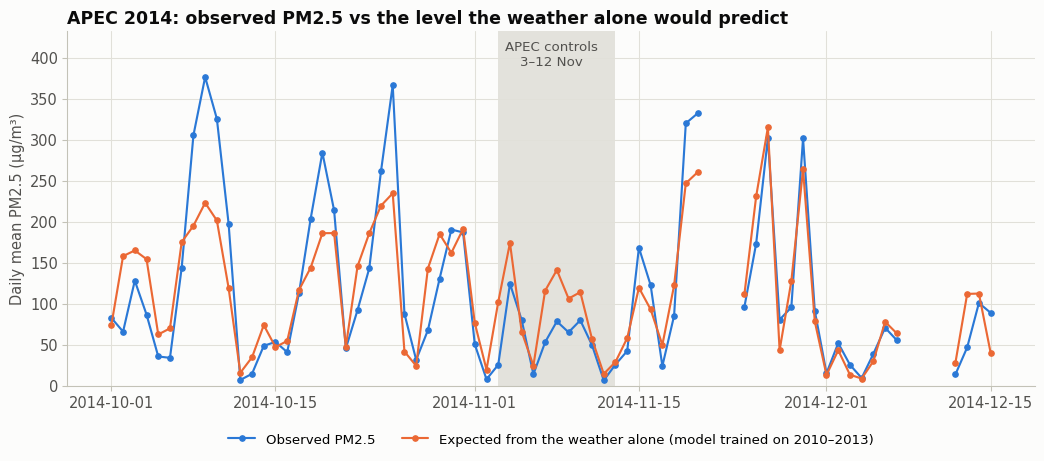

In [ ]:
# APEC chart: observed vs weather-expected PM2.5, October–December 2014 (Figure 16)
window_days = pd.date_range("2014-10-01", "2014-12-15", freq="D")       # missing days appear as gaps
obs_w, exp_w = y_test.reindex(window_days), expected.reindex(window_days)
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.axvspan(pd.Timestamp("2014-11-03"), pd.Timestamp("2014-11-12 23:59"), color=GRID, alpha=0.9, linewidth=0)
ax.text(pd.Timestamp("2014-11-07 12:00"), obs_w.max() * 1.12, "APEC controls\n3–12 Nov",
        ha="center", va="top", fontsize=10, color=INK2)
ax.plot(window_days, obs_w.values, color=BLUE, marker="o", markersize=4, linewidth=1.6, label="Observed PM2.5")
ax.plot(window_days, exp_w.values, color=ORANGE, marker="o", markersize=4, linewidth=1.6,
        label="Expected from the weather alone (model trained on 2010–2013)")
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("APEC 2014: observed PM2.5 vs the level the weather alone would predict")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set_ylim(0, obs_w.max() * 1.15)
save_fig("16_apec_meteorological_normalisation")
plt.show()